# 21 · Convergence with the resolution of the simulation (TNG50-2, -3, -4, the `simulations` sweep)


How much does the resolution of the hydrodynamical simulation matter? TNG50-2, -3 and -4 are the same 35 cMpc/$h$ box
at 8, 64 and 512 times the gas mass of TNG50-1, run with the same model; snapshot 25 is $z = 3$ in all three. The same
$128 \times 128$ lattice $x_i = i\,L/N$ puts the skewers at the **same places** in the three boxes, so the comparison is also
skewer by skewer. The fiducial options (along $y$, 1 km/s, the exact crossings, the integrated profile, the exact
frame; `run_production.py --sweep simulations`). The reference is TNG50-2, the finest available here. Three levels
are few, and the sub-grid model of TNG is calibrated at one resolution and does not converge strictly with it, so the
successive differences (TNG50-4 to -3 to -2) indicate the trend, not a converged answer.


Every run is a folder of `scripts/production/run_production.py` (`<OUT>/<SWEEP>/<run>/run.json`) that names its
lattice in the campaign's skewer store; `load_run` reads it. The statistics follow notebooks 11 and 18 on **one line of
sight** ($y$): the transmission $T = e^{-\tau}$ of every line and of the total, its mean $\bar T$, the overflux
$\delta = T/\bar T - 1$, P1D on its native modes and $P(k, \mu)$ of the total in four wedges, and both split
order by order and term by term on the 16 wedges of notebook 11 (`summary_stats.run_statistics`). One line of sight gives no ensemble, so the errors come from a **delete-one-block
jackknife**: the lattice is cut into $4 \times 4$ squares of skewers and each sample leaves one square out (the
3D power of the field with that square set to zero, divided by the fraction kept). Every run is compared with the
reference **bin by bin**, as the relative difference $X_{\rm run}/X_{\rm ref} - 1$, with the jackknife error of that
ratio (`compare_runs`): the runs share the skewer positions and the blocks, so the sample variance they share cancels.
The last part gives, per run, **the largest $k$ up to which every bin differs by less than 0.1%, 0.5% and 1%**
(`k_max_table`; P1D on every native mode, $P(k, \mu)$ on every $|k|$ bin).

Colours: the fiducial run of the campaign in black in every notebook; the other runs from light (coarse) to dark (fine)
on one scale shared by notebooks 18–21.


- **Part A — the stored skewers read back:** every run's lattice, pixels, sampling and dataset, and the checks of the
  pairing (one box size, one redshift, the same positions).
- **Part B — the statistics of every run** and their comparison with the reference.
- **Part C — the mean transmission.**
- **Part D — P1D by order and by term:** D1 the total and orders 2–4, D2 the order-2 terms (the autos of
  $\mathrm{Ly}\alpha$ and Si III, their cross), every run against TNG50-2. D1 ends with the successive steps of P1D, TNG50-4 to -3 to -2.
- **Part E — $P(k, \mu)$ by order and by term in 16 wedges:** E1 the total and orders 2–4, E2 the order-2 terms,
  one figure each.
- **Part F — the converged range:** the largest $k$ within 0.1%, 0.5% and 1% of the reference, and what it implies.

In [1]:
import os
from pathlib import Path

# ---- configuration: the sweep (scripts/production/run_production.py --sweep simulations)
SWEEP = "simulations"
RUNS = ["TNG50-4", "TNG50-3", "TNG50-2"]          # coarse to fine
REFERENCE = "TNG50-2"                             # the finest simulation: the reference
FIDUCIAL = "TNG50-2"                              # the fiducial run (black in every figure)
TERMS_REF = REFERENCE                             # the reference of Parts D and E: TNG50-2, the finest simulation
ORDER = ["TNG50-4", "TNG50-3", None, None, "TNG50-2"]   # on the colour scale of the four notebooks: coarsest, ..., finest
RUN_LABELS = {r: r for r in RUNS}
TITLE_STEM = "Simulation resolution"
LINTHRESH = 0.01                                  # [%]
OUT = Path(os.environ.get("SKEWERJAX_PRODUCTION", Path.home() / "skewerjax_production"))   # the --out of the campaign
N_SUB = None                                      # None: each run's lattice; 32: a quick check on the nested 32^2 sub-lattice
N_BLOCKS = 4                                      # jackknife: N_BLOCKS x N_BLOCKS squares of skewers
MU_EDGES = (0.0, 0.5, 0.8, 0.95, 1.0)             # the four wedges of P(k, mu) (notebooks 10 and 11's wedges of xi)
TOLS = (0.001, 0.005, 0.01)                       # the convergence levels of Part F
N_MU_TERMS = 16                                   # Parts D and E: the wedges of notebook 11, even in the angle to the line of sight
RES_LINTHRESH = 1.0                               # [%]: the residual rows of Parts D and E are linear within it

X_OF_RUN, X_LABEL, X_SCALE = {"TNG50-4": 19250411, "TNG50-3": 152305397}, "gas cells of the simulation", "log"
X_TICKS = {"TNG50-4": "TNG50-4", "TNG50-3": "TNG50-3"}

# ---- imports
os.environ.setdefault("JAX_PLATFORMS", "cpu")
import logging; logging.getLogger("jax._src.xla_bridge").setLevel(logging.CRITICAL)
import json, sys, time
import numpy as np
import matplotlib.pyplot as plt
from skewerjax.utils.plotting import use_style, use_backend
# use_backend()                                    # interactive figures in a live notebook
use_style()
from skewerjax.utils.plotting import (TERM_ORDERS, add_panel_letters, field_names, order2_terms, run_styles,
                                      plot_runs_mean_flux, plot_runs_p1d_orders, plot_runs_p1d_terms, plot_runs_pk_mu_orders,
                                      plot_runs_pk_mu_terms, plot_k_max_summary)
from skewerjax.summary_stats import (LatticeWedges, block_labels, compare_runs, format_k_max_table, format_terms_table,
                                     k_max_table, rebin_pixels, run_statistics, set_k_edges)
from skewerjax.utils.reference_data import P1D_DESI_DR1, nearest_reference
from skewerjax.utils.paths import PRODUCTION_DIR, PRODUCTION_SCRIPTS_DIR   # the run folders; the reader of the skewer store
sys.path.insert(0, str(PRODUCTION_SCRIPTS_DIR))
from skewer_store import load_run
from skewerjax.utils.plotting import PALETTE

## Part A — The stored skewers read back

- `OUT`, `SWEEP`, `RUNS`: the run folders `<OUT>/<SWEEP>/<run>`; `REFERENCE` TNG50-2.
- `N_SUB`: `None` reads the $128 \times 128$ lattices; 32 the nested $32 \times 32$ sub-lattices (a quick check).

The checks: the three boxes have the same size and the snapshots the same redshift, so the lattice puts the skewers at
the same comoving positions and the pixels on the same velocities. Then, skewer by skewer, how far the transmissions
of the coarser simulations are from TNG50-2's: the rms of $F_{\rm run} - F_{\rm ref}$ over the pixels and the
correlation coefficient of the two overfluxes, per skewer.

In [2]:
RECS = {r: json.loads((OUT / SWEEP / r / "run.json").read_text()) for r in RUNS}
S = {r: load_run(OUT / SWEEP / r, N_SUB) for r in RUNS}          # tau (n_lines, N_sk, N_pix), positions, columns, v, dv, L, u
REF = S[REFERENCE]
L, U, PERIOD = REF.L, REF.u, REF.period                          # [cMpc], aH [km/s per cMpc], v_per [km/s]
N = REF.n_per_axis
Z, A_SNAP = RECS[REFERENCE]["snapshot"]["redshift"], RECS[REFERENCE]["snapshot"]["a"]
LINE_IDS = REF.line_ids
FIELDS = (*LINE_IDS, "total")
NAMES = field_names(FIELDS)
print(f"{'run':<13} {'sim':<8} {'lattice':>8} {'N_pix':>6} {'dv [km/s]':>10} {'dx [cMpc]':>10} {'dx [km/s]':>10} {'route':<10} "
      f"{'dataset':<11} {'computed':>8} {'wall':>8}")
for r in RUNS:
    rec, s, sm = RECS[r], S[r], RECS[r]["sampling"]
    print(f"{r:<13} {s.sim:<8} {s.n_per_axis:>5}^2 {s.v.size:>6} {s.dv:>10.4f} {sm['points_cMpc']:>10.3g} {sm['points_kms']:>10.3g} "
          f"{sm['route']:<10} {rec['dataset']['hash']:<11} {rec['timings']['computed']:>8} {rec['wall_s']:>7.0f}s")
    assert np.isfinite(s.tau).all(), r
for r in RUNS:                                    # tau < 0: the round-off of the engine (float32), relative to each skewer's peak
    t = S[r].tau
    neg = t < 0
    if neg.any():
        worst = (-t.min(axis=-1) / t.max(axis=-1)).max(axis=-1)       # (n_lines,) the largest |tau_min| / tau_max of a skewer
        print(f"{r}: tau < 0 in {neg.mean():.2%} of the samples (" + ", ".join(
              f"{NAMES[l]}: min {t[j].min():.2g}, |min| / max per skewer <= {worst[j]:.1e}" for j, l in enumerate(LINE_IDS) if t[j].min() < 0) + ")")
print(f"\nreference {REFERENCE}: {REF.sim} snapshot {REF.snap}, z = {Z:.4f}, L = {L:.3f} cMpc, u = {U:.3f} km/s per cMpc (1 km/s = {1 / U:.5f} cMpc), "
      f"v_per = {PERIOD:.2f} km/s; tau finite in every run")
print("sampling of the reference: " + RECS[REFERENCE]["sampling"]["effect"])

for r in RUNS:
    sn = RECS[r]["snapshot"]
    assert abs(sn["box_cMpc"] - L) < 1e-9 * L and abs(sn["redshift"] - Z) < 1e-9, r
    assert np.array_equal(S[r].positions, REF.positions) and np.array_equal(S[r].v, REF.v), r
print("box size and redshift: " + "; ".join(f"{r}: L = {RECS[r]['snapshot']['box_cMpc']:.6f} cMpc, z = {RECS[r]['snapshot']['redshift']:.6f}, "
                                           f"{RECS[r]['snapshot']['n_gas']:,} gas cells" for r in RUNS))
F_REF = np.exp(-REF.tau)
for r in RUNS:
    if r == REFERENCE:
        continue
    F = np.exp(-S[r].tau)
    rms = np.sqrt(np.mean((F - F_REF) ** 2, axis=-1))                     # (n_lines, N_sk)
    dF, dR = F / F.mean() - 1, F_REF / F_REF.mean() - 1
    rho = np.sum(dF * dR, -1) / np.sqrt(np.sum(dF**2, -1) * np.sum(dR**2, -1))
    print(f"{r} vs {REFERENCE}, per skewer, median [16th, 84th percentile]: " + "; ".join(
        f"{NAMES[l]}: rms(F - F_ref) {np.median(rms[j]):.3g} [{np.percentile(rms[j], 16):.3g}, {np.percentile(rms[j], 84):.3g}], "
        f"correlation {np.median(rho[j]):.3f} [{np.percentile(rho[j], 16):.3f}, {np.percentile(rho[j], 84):.3f}]" for j, l in enumerate(LINE_IDS)))
del F_REF, F

run           sim       lattice  N_pix  dv [km/s]  dx [cMpc]  dx [km/s] route      dataset     computed     wall
TNG50-4       TNG50-4    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9     16384      26s
TNG50-3       TNG50-3    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9     16384      50s
TNG50-2       TNG50-2    128^2   3949     1.0002       0.05       3.83 streaming  e228cdc7b9         0       1s

reference TNG50-2: TNG50-2 snapshot 25, z = 3.0081, L = 51.668 cMpc, u = 76.673 km/s per cMpc (1 km/s = 0.01304 cMpc), v_per = 3949.82 km/s; tau finite in every run
sampling of the reference: the a(s) table of the exact frame every 0.05 cMpc; not the pieces (the exact cell crossings need no sampling points)
box size and redshift: TNG50-4: L = 51.668143 cMpc, z = 3.008131, 19,250,411 gas cells; TNG50-3: L = 51.668143 cMpc, z = 3.008131, 152,305,397 gas cells; TNG50-2: L = 51.668143 cMpc, z = 3.008131, 1,205,098,922 gas cells
TNG50-4 vs TNG50-2, 

## Part B — The statistics of every run

The 3D bins are set by the lattice: $|k|$ one bin per mode up to $3.5\,k_f$, steps of $0.4\,k_f$
to 2 cMpc$^{-1}$, then 12 logarithmic bins to the transverse Nyquist frequency $\pi N/L$; the four wedges of
`MU_EDGES` in $\mu = k_\parallel/|k|$. P1D stays on its native modes $k_m = 2\pi m/v_{\rm per}$ for the checks, and is
averaged in 40 logarithmic bins for the figures only. Each line gives the time of each step of a run.

Then the successive comparisons: TNG50-3 against TNG50-4 and TNG50-2 against TNG50-3 (the same jackknife blocks).

**The decomposition of Parts D and E:** `run_statistics(terms_grid=)` also splits P1D and $P(k, \mu)$ of the total
into its orders and order-2 terms, with the same jackknife, in the 16 wedges of `MU_EDGES_TERMS` on the same $|k|$
bins (`LatticeWedges(store_index=False)`: the transforms along the line of sight first, then across the lattice one
slab of $k_\parallel$ at a time). Two checks are printed per run: the sum of the orders against the total (the sum
rule), and the total against P1D and the four wedges of $P(k, \mu)$ above (the largest difference relative to the
largest value).

In [3]:
KF = 2 * np.pi / L
K_NYQ = np.pi * N / L                                            # the transverse Nyquist frequency of the lattice [1/cMpc]
K_EDGES = set_k_edges(KF, k_1=3.5 * KF, k_2=min(2.0, K_NYQ), k_max=K_NYQ, dk_factor=0.4, n_log=12)
K1D_EDGES = np.geomspace(2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in RUNS), 41)   # display bins of P1D [s/km]
P1D_REF = nearest_reference(P1D_DESI_DR1, Z)
K_DESI = float(np.max(P1D_REF["k"]))                             # [s/km]: the largest k of DESI DR1 at the snapshot's z
MU_EDGES_TERMS = np.sin(np.linspace(0.0, np.pi / 2, N_MU_TERMS + 1))   # the wedges of Parts D and E
GRIDS = {}


def grid_for(n, n_pix):
    """The mu wedges of P on an n x n lattice of n_pix pixels (LatticeWedges: the bins of lattice_grid's P_mu alone, the memory of
    512^2 lattices), cached: the same |k| edges and mu wedges for every run."""
    if (n, n_pix) not in GRIDS:
        GRIDS[n, n_pix] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES)
    return GRIDS[n, n_pix]


def terms_grid_for(n, n_pix):
    """The 16 wedges of the decomposition (Parts D and E), without an index (streamed by run_statistics)."""
    if (n, n_pix, "terms") not in GRIDS:
        GRIDS[n, n_pix, "terms"] = LatticeWedges(n, n_pix, L, k_edges=K_EDGES, mu_edges=MU_EDGES_TERMS, store_index=False)
    return GRIDS[n, n_pix, "terms"]


def statistics(s, transmissions=None, n_pix=None, dv=None, decompose=True):
    """run_statistics of one run (or of ``transmissions`` on ``n_pix`` pixels of ``dv``) on its lattice's jackknife blocks
    and bins, T_bar the mean over every pixel (one scale factor: the box), with the time of each step; with its
    decomposition by order and term on the 16 wedges (decompose=False: the total alone)."""
    n_pix = s.v.size if n_pix is None else n_pix
    steps = []
    out = run_statistics(None if transmissions is not None else s.tau, s.dv if dv is None else dv, line_ids=LINE_IDS,
                         labels=block_labels(s.columns, s.n_per_axis, N_BLOCKS), grid=grid_for(s.n_per_axis, n_pix),
                         transmissions=transmissions, a_pix=np.full(n_pix, A_SNAP), log=steps.append,
                         terms_grid=terms_grid_for(s.n_per_axis, n_pix), decompose=decompose)
    return out, steps


STATS, T0 = {}, time.perf_counter()
for r in RUNS:
    t = time.perf_counter()
    STATS[r], steps = statistics(S[r])
    print(f"{r:<13} {time.perf_counter() - t:6.1f} s: " + "; ".join(steps))
    tr = STATS[r]["terms"]
    print(f"{'':<13} sum of the orders vs the total: P1D {tr['sum_rule']['p1d']:.1e}, P(k, mu) {tr['sum_rule']['P_mu']:.1e}; "
          f"the total vs P1D and the 4 wedges above: {tr['check']['p1d']:.1e}, {tr['check']['P_mu']:.1e}")
CMP = {r: compare_runs(STATS[r], STATS[REFERENCE], k_edges_1d=K1D_EDGES) for r in RUNS if r != REFERENCE}   # display bins
CMP_ALL = {r: compare_runs(STATS[r], STATS[REFERENCE]) for r in RUNS if r != REFERENCE}                  # every mode: the checks
STYLES = run_styles(ORDER, fiducial=FIDUCIAL)
CMP_T = CMP                                                      # Parts D and E: against TERMS_REF
print(f"every run in {time.perf_counter() - T0:.0f} s; P(k, mu) in {len(MU_EDGES) - 1} wedges x {len(K_EDGES) - 1} |k| bins up to "
      f"{K_NYQ:.2f} cMpc^-1; jackknife over {N_BLOCKS} x {N_BLOCKS} squares of {N // N_BLOCKS} x {N // N_BLOCKS} skewers")

CMP_STEP = {"TNG50-3": compare_runs(STATS["TNG50-3"], STATS["TNG50-4"], k_edges_1d=K1D_EDGES),
            "TNG50-2": compare_runs(STATS["TNG50-2"], STATS["TNG50-3"], k_edges_1d=K1D_EDGES)}
CMP_STEP_ALL = {"TNG50-3": compare_runs(STATS["TNG50-3"], STATS["TNG50-4"]),
                "TNG50-2": compare_runs(STATS["TNG50-2"], STATS["TNG50-3"])}
STEP_LABELS = {"TNG50-4": "TNG50-4", "TNG50-3": "TNG50-3 / TNG50-4", "TNG50-2": "TNG50-2 / TNG50-3"}
TERMS = order2_terms(CMP_T)                                      # the order-2 terms of D2 and E2: the autos, the cross
K_LIMITS_T = (2 * np.pi / PERIOD, np.pi / min(S[r].dv for r in CMP_T))   # [s/km]: the P1D range the runs share with TERMS_REF


TNG50-4         81.7 s: transmissions of 16,384 skewers x 3949 pixels (2.1 s); P1D of HI-LyA (2.1 s); P1D of SiIII-1206 (2.0 s); P1D of total (1.9 s); P(k, mu) of total and its 16 jackknife samples (13.7 s); the transforms along the line of sight and P1D of 11 pairs (28.0 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (26.2 s)
              sum of the orders vs the total: P1D 1.8e-09, P(k, mu) 8.1e-08; the total vs P1D and the 4 wedges above: 7.3e-16, 5.8e-08
TNG50-3         82.8 s: transmissions of 16,384 skewers x 3949 pixels (1.5 s); P1D of HI-LyA (2.9 s); P1D of SiIII-1206 (3.2 s); P1D of total (2.5 s); P(k, mu) of total and its 16 jackknife samples (18.4 s); the transforms along the line of sight and P1D of 11 pairs (28.2 s); P(k, mu) of 11 pairs and their 16 jackknife samples in slabs of 32 k_par (26.0 s)
              sum of the orders vs the total: P1D 2.1e-09, P(k, mu) 4.2e-08; the total vs P1D and the 4 wedges above: 3.6e-16, 1.5e-07
TNG50-2     

## Part C — The mean transmission

$\bar F$ of every line and of the total, per run, as $100\,(\bar F_{\rm run}/\bar F_{\rm ref} - 1)$ [%] with its
jackknife error (the reference is the line at 0; the grey band is $\pm 0.5\%$, the dotted lines $\pm 0.1\%$ and
$\pm 1\%$; the axis is linear within `LINTHRESH`).

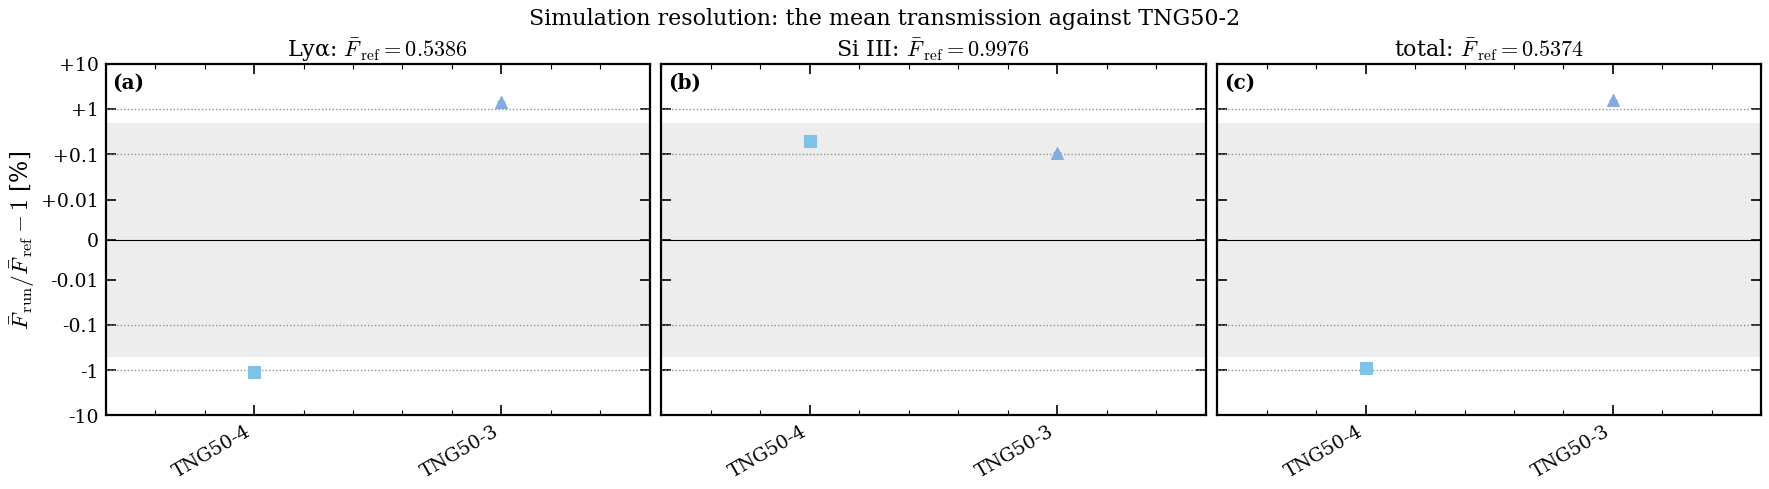

TNG50-4       Lyα: -1.09 +- 0.16 %; Si III: +0.198 +- 0.015 %; total: -0.903 +- 0.15 %
TNG50-3       Lyα: +1.45 +- 0.066 %; Si III: +0.106 +- 0.0084 %; total: +1.56 +- 0.065 %


In [4]:
fig, axs = plot_runs_mean_flux(CMP, STYLES, REFERENCE, field_labels=NAMES, labels=RUN_LABELS, linthresh=LINTHRESH,
                               title=f"{TITLE_STEM}: the mean transmission against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()
for r, c in CMP_ALL.items():
    print(f"{r:<13} " + "; ".join(f"{NAMES[f]}: {100 * c['mean_flux']['rel'][j]:+.3g} +- {100 * c['mean_flux']['err'][j]:.2g} %"
                                  for j, f in enumerate(FIELDS)))

## Part D — P1D by order and by term

**The orders and the terms** (notebook 11, Parts E and F; `docs/decomposition.md`). With $\delta_j = T_j/\bar T_j - 1$
the overflux of line $j$ and $\mathcal C = \bar T/\prod_j \bar T_j - 1$, the total overflux is exactly a sum of subset
fields, $\delta_{\rm tot} = \sum_A F_A$, with $F_\emptyset = -\mathcal C/(1+\mathcal C)$ and
$F_A = \prod_{j\in A}\delta_j/(1+\mathcal C)$. Every two-point statistic of the total is then the sum of the
cross-statistics of the pairs $(A, B)$, grouped by the order $n = |A| + |B| = 0, \dots, 4$ for two lines:

* **order 2:** the $\mathrm{Ly}\alpha$ auto ($F_{\rm Ly\alpha}$ with itself), the Si III auto, their cross
  ($2\,\mathrm{Re}\,P_{\rm Ly\alpha, Si\,III}$, which oscillates as $\cos(k_\parallel \Delta v)$ with the separation
  $\Delta v$ of the lines) and a $\mathcal C$ term;
* **order 3:** each line with the product of the two; **order 4:** the product with itself.

**Orders 0 and 1 are not shown.** They hold only the $\mathcal C$ terms, the corrections of the mean, which vanish on
average. In one snapshot $\mathcal C$ is a single number (`MEAN = "redshift"` with one $a$), so $F_\emptyset$ is a
constant whose power lives at $k = 0$ alone, which P1D at $k > 0$ and $P(k, \mu)$ leave out; the $\mathcal C$ term of
order 2 vanishes alike. At every $k > 0$: total = order 2 + order 3 + order 4 (the sum rule printed in Part B).

**The figures.** Every run against **TNG50-2** (the highest level of the sweep), drawn thick and light underneath with
its jackknife error as a faint band. Above, $kP_{\rm 1D}/\pi$ in 40 logarithmic display bins. Below, the difference
$\Delta = X_{\rm run} - X_{\rm ref}$ in per cent of $|X_{\rm ref}|$, on the grey band of the reference's jackknife error:
a residual inside the band is not significant. The residual axis is symmetric-log, linear within `RES_LINTHRESH`. A
quantity that changes sign (the cross term, order 3) has a symmetric-log main axis, and where $|X_{\rm ref}|$ falls
below 1% of its maximum in the panel, $\Delta$ is divided by the local envelope of $|X_{\rm ref}|$ instead (its running
maximum over $\pm 2$ bins; open markers). The grey bands lie outside $[2\pi/v_{\rm per}, \pi/dv]$; the dashed line is the
largest $k$ of DESI DR1 at the snapshot's redshift. The tables list, per run and quantity for $k \le k_{\rm DESI}$, the median and largest $|\Delta|$, the median error of the reference, and the share of bins
outside it.

### D1 · P1D by order

The total and orders 2, 3, 4.

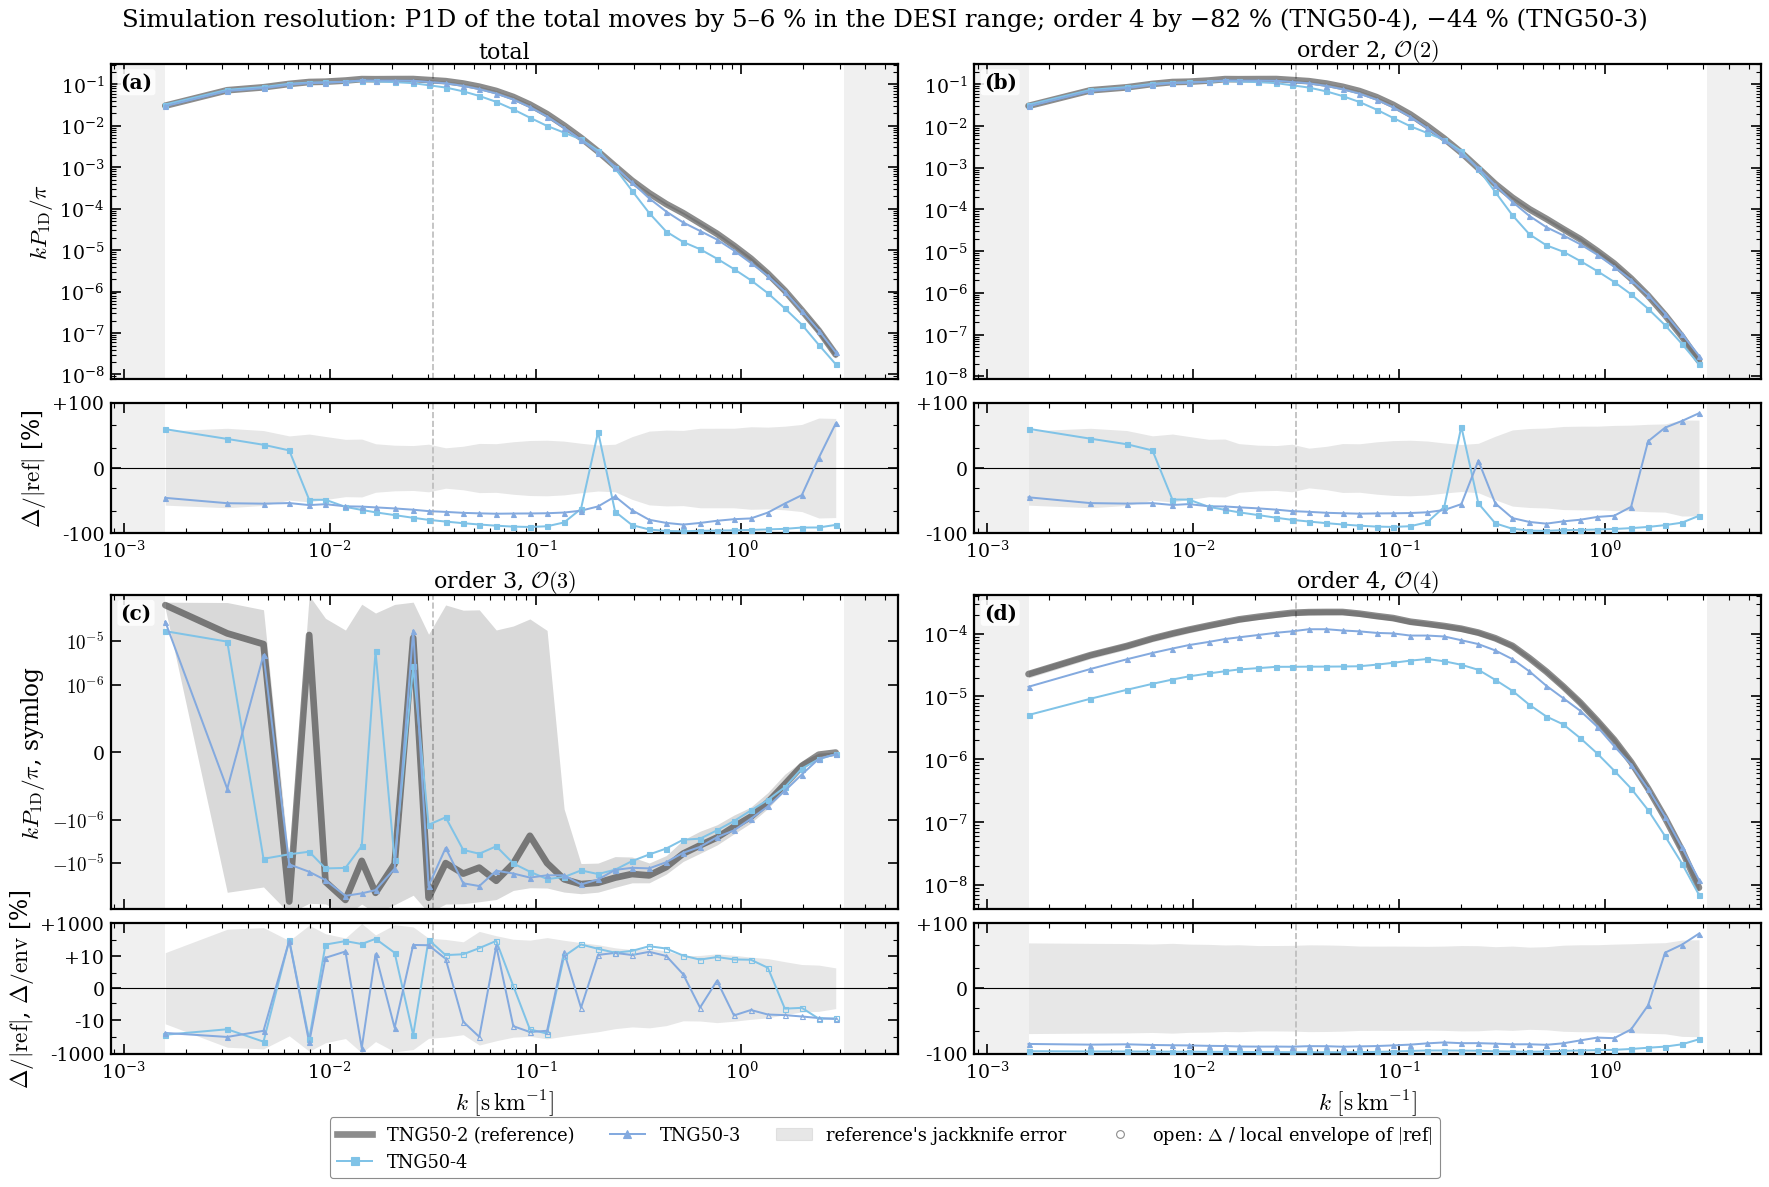

k <= 0.032 s/km, against TNG50-2:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        total                                  6.72         25.1        2.81      67%
TNG50-4        order 2                                6.82           25        2.82      58%
TNG50-4        order 3                                79.8          194         319      17%
TNG50-4        order 4                                82.3         86.2        11.3     100%
TNG50-3        total                                  5.97         10.4        2.81      75%
TNG50-3        order 2                                5.92         10.3        2.82      75%
TNG50-3        order 3                                47.3          460         319       8%
TNG50-3        order 4                                44.1         49.2        11.3     100%


In [5]:
fig, main, res = plot_runs_p1d_orders(CMP_T, STYLES, TERMS_REF, line_ids=LINE_IDS, labels=RUN_LABELS, linthresh=RES_LINTHRESH,
                                      k_limits=K_LIMITS_T, k_mark=K_DESI,
                                      title='Simulation resolution: P1D of the total moves by 5–6 % in the DESI range; order 4 by −82 % (TNG50-4), −44 % (TNG50-3)')
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERM_ORDERS, "p1d", k_max=K_DESI))

*Reading.* In the DESI range the total and order 2 are 5.0% (TNG50-4) and 6.0% (TNG50-3) below TNG50-2
(median), outside its 2.8% error; above 0.1 s/km TNG50-4 falls to $-59$%. Order 4 reacts far more: $-82$% and $-44$%,
every bin outside its 11% error. Order 3 is noise. The resolution changes the metal terms most.

**The successive steps of P1D** (`CMP_STEP`, Part B): the change at each step of resolution (a factor 8 in mass,
2 in length). If the simulations converged geometrically, the second step would be smaller than the first by
a constant factor $q$, and the error left in TNG50-2 would be about the second step over $q - 1$. The printout
gives $q$ in the DESI range (the median over the modes of the ratio of the two steps) where both steps exceed
their errors.

In [6]:
k = CMP_STEP_ALL["TNG50-2"]["p1d"]["k"]
for j, f in enumerate(FIELDS):
    d1, e1 = CMP_STEP_ALL["TNG50-3"]["p1d"]["rel"][j], CMP_STEP_ALL["TNG50-3"]["p1d"]["err"][j]
    d2, e2 = CMP_STEP_ALL["TNG50-2"]["p1d"]["rel"][j], CMP_STEP_ALL["TNG50-2"]["p1d"]["err"][j]
    sel = (k <= K_DESI) & (np.abs(d1) > 2 * e1) & (np.abs(d2) > 2 * e2) & (np.sign(d1) == np.sign(d2))
    q = np.median(d1[sel] / d2[sel]) if sel.sum() > 3 else np.nan
    print(f"P1D {NAMES[f]}, k <= {K_DESI:.3f} s/km: median |step| 4->3 {100 * np.median(np.abs(d1[k <= K_DESI])):.2g} %, "
          f"3->2 {100 * np.median(np.abs(d2[k <= K_DESI])):.2g} %; q = step(4->3) / step(3->2) = {q:.2f} on {sel.sum()} modes"
          + (f"; geometric extrapolation of the error left in TNG50-2: ~{100 * np.median(np.abs(d2[sel])) / (q - 1):.2g} %" if q > 1 else ""))

P1D Lyα, k <= 0.032 s/km: median |step| 4->3 7.4 %, 3->2 7.5 %; q = step(4->3) / step(3->2) = 1.20 on 11 modes; geometric extrapolation of the error left in TNG50-2: ~42 %
P1D Si III, k <= 0.032 s/km: median |step| 4->3 2.2e+02 %, 3->2 89 %; q = step(4->3) / step(3->2) = 2.40 on 19 modes; geometric extrapolation of the error left in TNG50-2: ~64 %
P1D total, k <= 0.032 s/km: median |step| 4->3 6.9 %, 3->2 7.6 %; q = step(4->3) / step(3->2) = 1.18 on 11 modes; geometric extrapolation of the error left in TNG50-2: ~48 %


### D2 · P1D term by term (order 2)

The $\mathrm{Ly}\alpha$ auto, the Si III auto and their cross term.

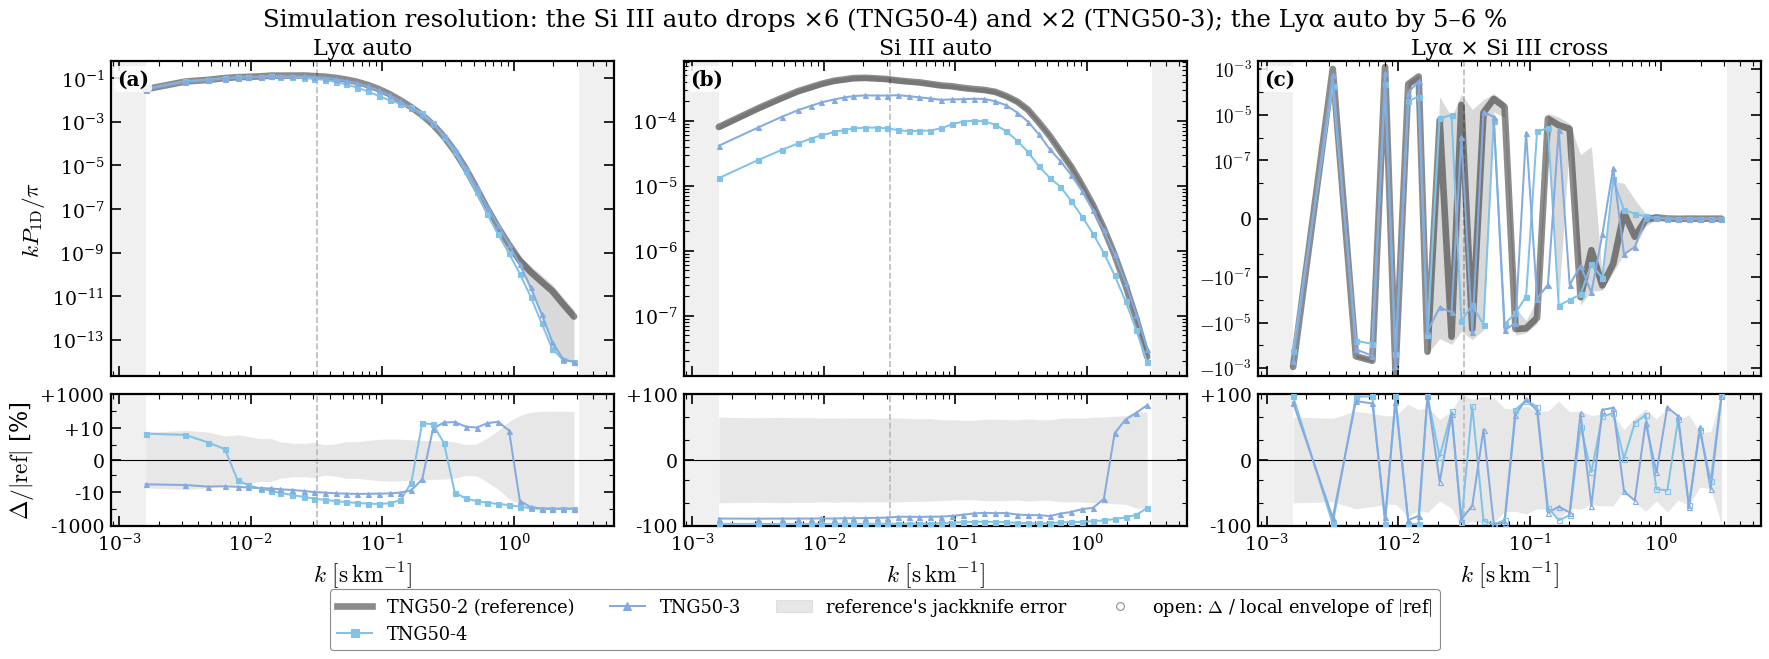

k <= 0.032 s/km, against TNG50-2:
run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        HI-LyA|HI-LyA                          5.51         24.8        2.81      58%
TNG50-4        SiIII-1206|SiIII-1206                  83.7         84.2        9.26     100%
TNG50-4        HI-LyA|SiIII-1206                      81.3         86.9        15.7      83%
TNG50-3        HI-LyA|HI-LyA                          5.76         10.2        2.81      75%
TNG50-3        SiIII-1206|SiIII-1206                  48.2         49.4        9.26     100%
TNG50-3        HI-LyA|SiIII-1206                      43.9         87.4        15.7      75%


In [7]:
fig, main, res = plot_runs_p1d_terms(CMP_T, STYLES, TERMS_REF, terms=TERMS, line_ids=LINE_IDS, labels=RUN_LABELS,
                                     linthresh=RES_LINTHRESH, k_limits=K_LIMITS_T,
                                     k_mark=K_DESI, title="Simulation resolution: the Si III auto drops ×6 (TNG50-4) and ×2 (TNG50-3); the Lyα auto by 5–6 %")
add_panel_letters(main)
plt.show()
print(f"k <= {K_DESI:.3f} s/km, against {TERMS_REF}:")
print(format_terms_table(CMP_T, TERMS, "p1d", k_max=K_DESI))

*Reading.* The $\mathrm{Ly}\alpha$ auto follows the total ($-5.1$%, $-5.8$% in the DESI range). The Si III
auto is $-84$% (TNG50-4) and $-48$% (TNG50-3) below TNG50-2 at every $k$: the dense, enriched gas that absorbs in Si III
is resolved better at each step, and it has not converged. The cross departs by 80% (TNG50-4) and 44% (TNG50-3) of its
envelope.

## Part E — The wedges of $P(k, \mu)$ by order and by term

The 3D counterpart of Part D: $P(k, \mu)$ of the total overflux, of its orders and of its order-2 terms in the 16 wedges
of notebook 11 (`MU_EDGES_TERMS`, evenly spaced in the angle to the line of sight; Part F keeps the four wedges of
`MU_EDGES`), on the $|k|$ bins of Part B. Each quantity has one figure, with the wedges in the grid of notebook 11 (F1)
and a residual row under each wedge, as in Part D. A cell without modes is not drawn. The tables list, per run and
quantity over every wedge and bin, the same numbers as in Part D.

### E1 · The wedges by order

One figure each for the total and orders 2, 3, 4.

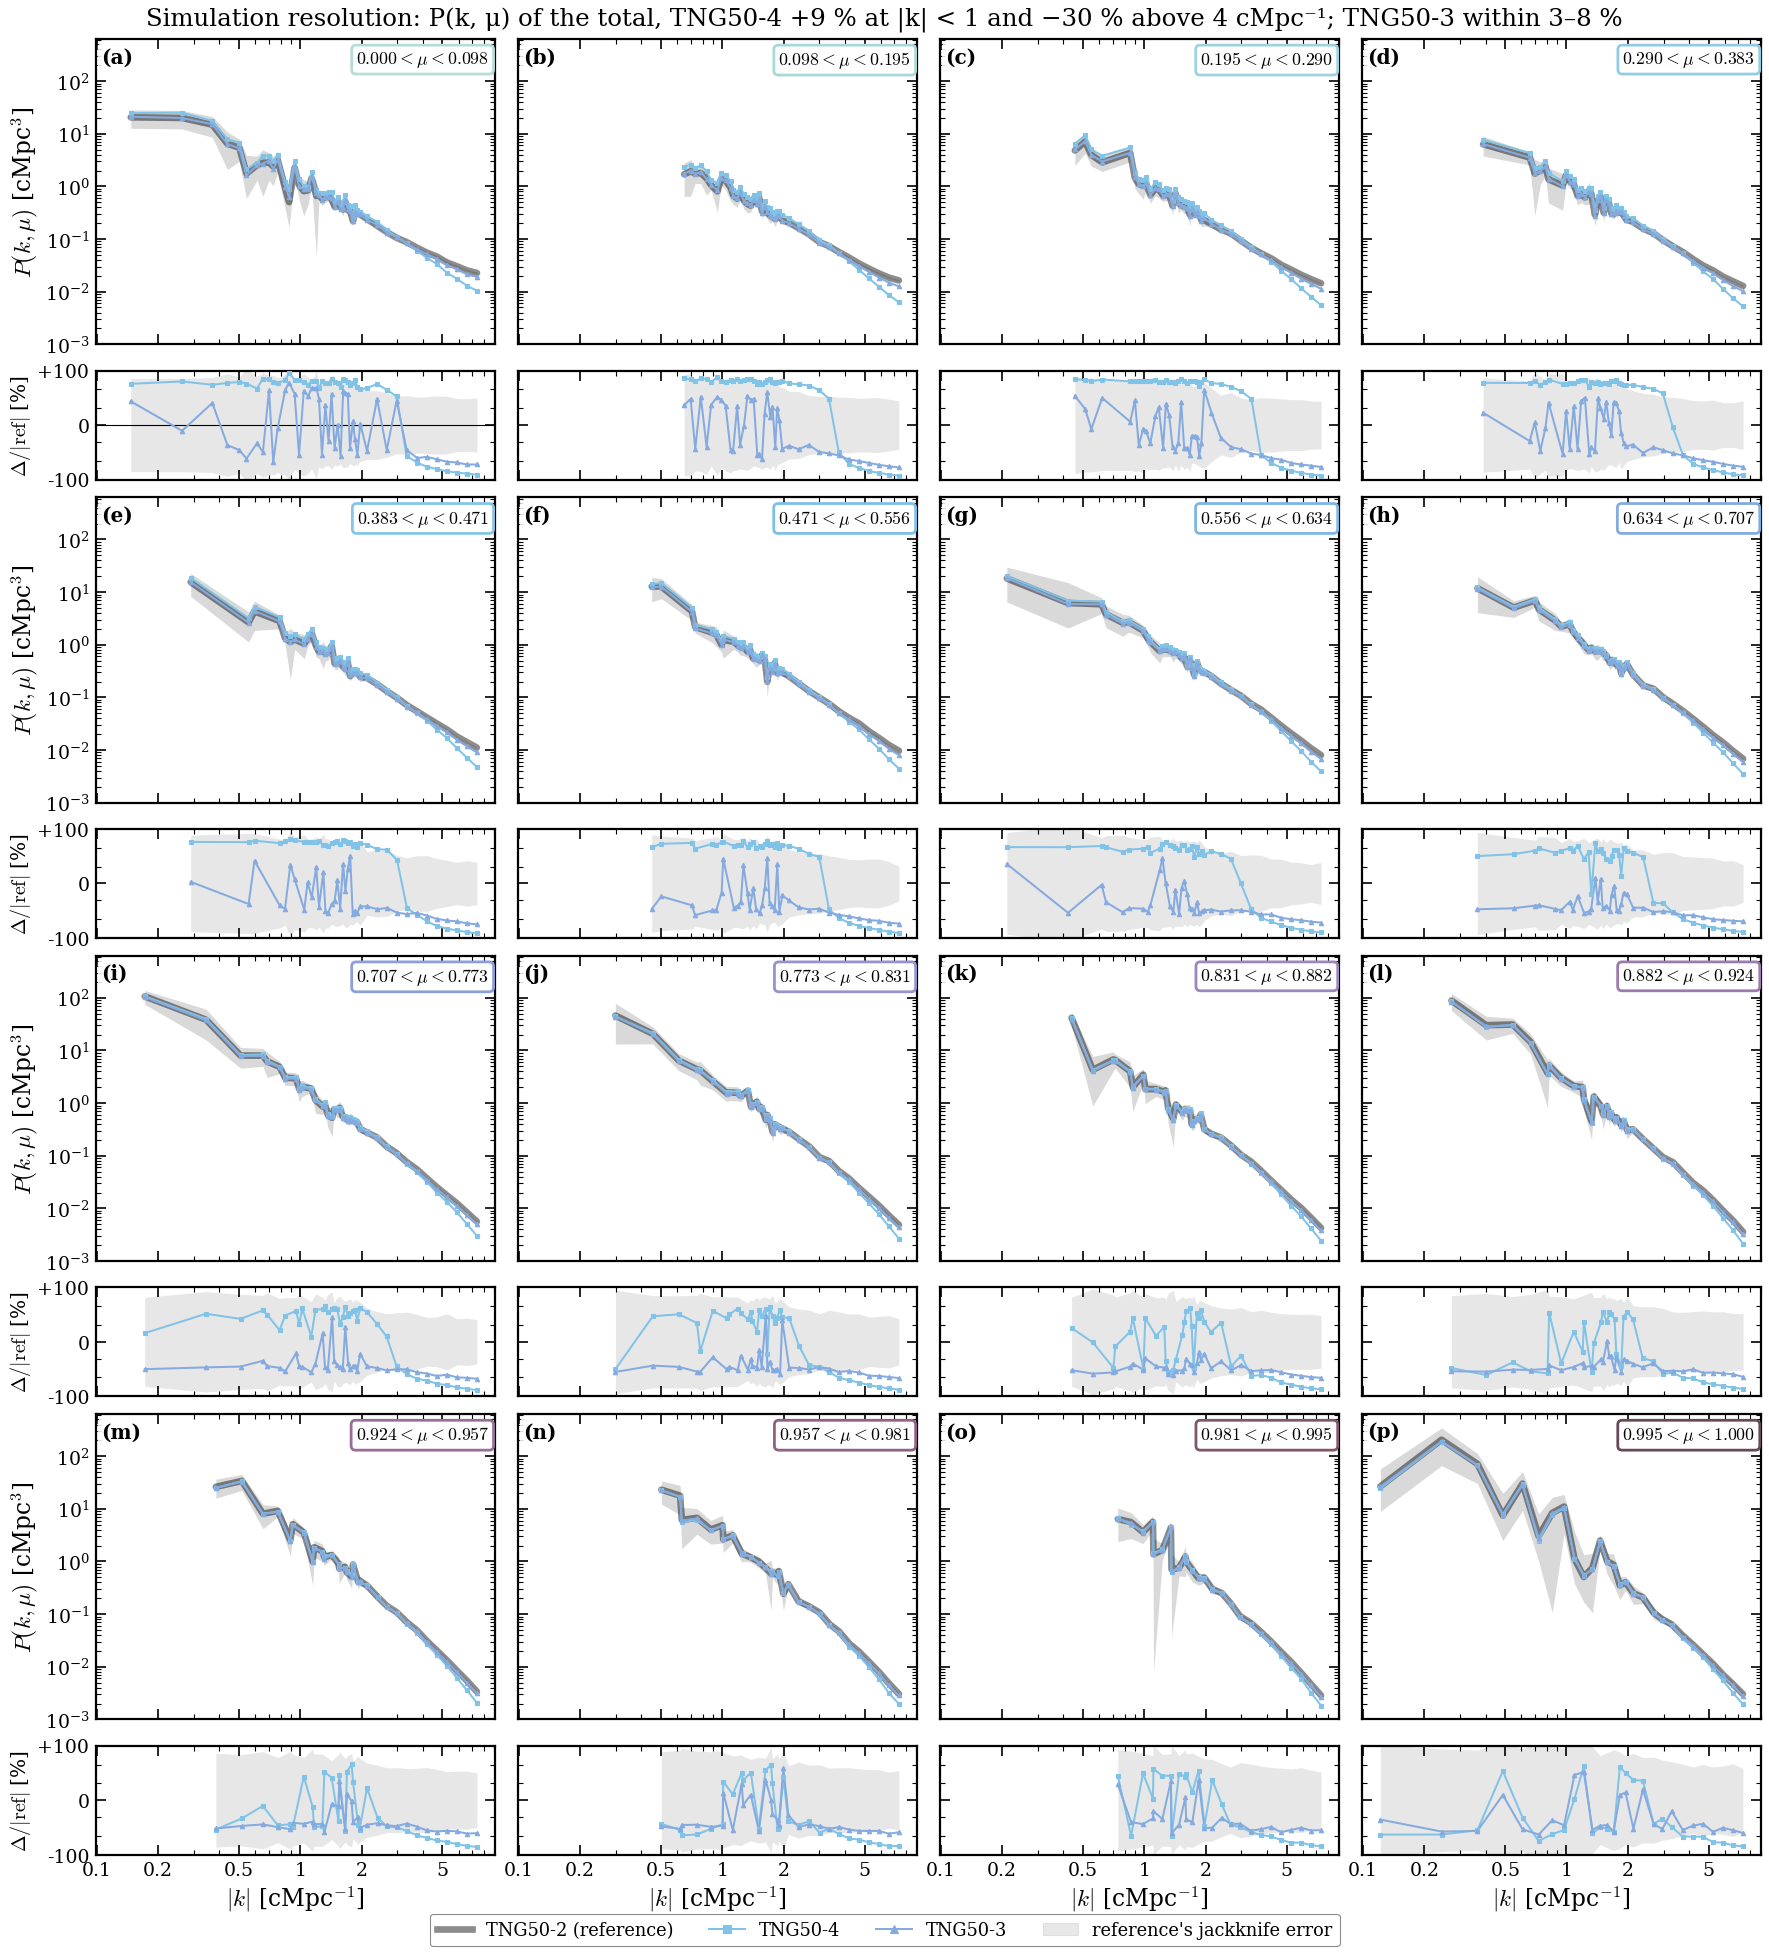

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        total                                  10.7         74.4        21.9      33%
TNG50-3        total                                  2.95         22.9        21.9      17%


In [8]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('total',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'total': "Simulation resolution: P(k, μ) of the total, TNG50-4 +9 % at |k| < 1 and −30 % above 4 cMpc⁻¹; TNG50-3 within 3–8 %"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('total',), "P_mu"))

*Reading (total).* TNG50-4 is $+9$% above TNG50-2 at $|k| < 1$ cMpc$^{-1}$ and $-30$% below at $|k| > 4$
cMpc$^{-1}$ (medians over the wedges); TNG50-3 $-2.4$% and $-8$%. Low-$|k|$ bins are inside the 22% jackknife error of
the $128^2$ lattice; the high-$|k|$ deficit of TNG50-4 is not.

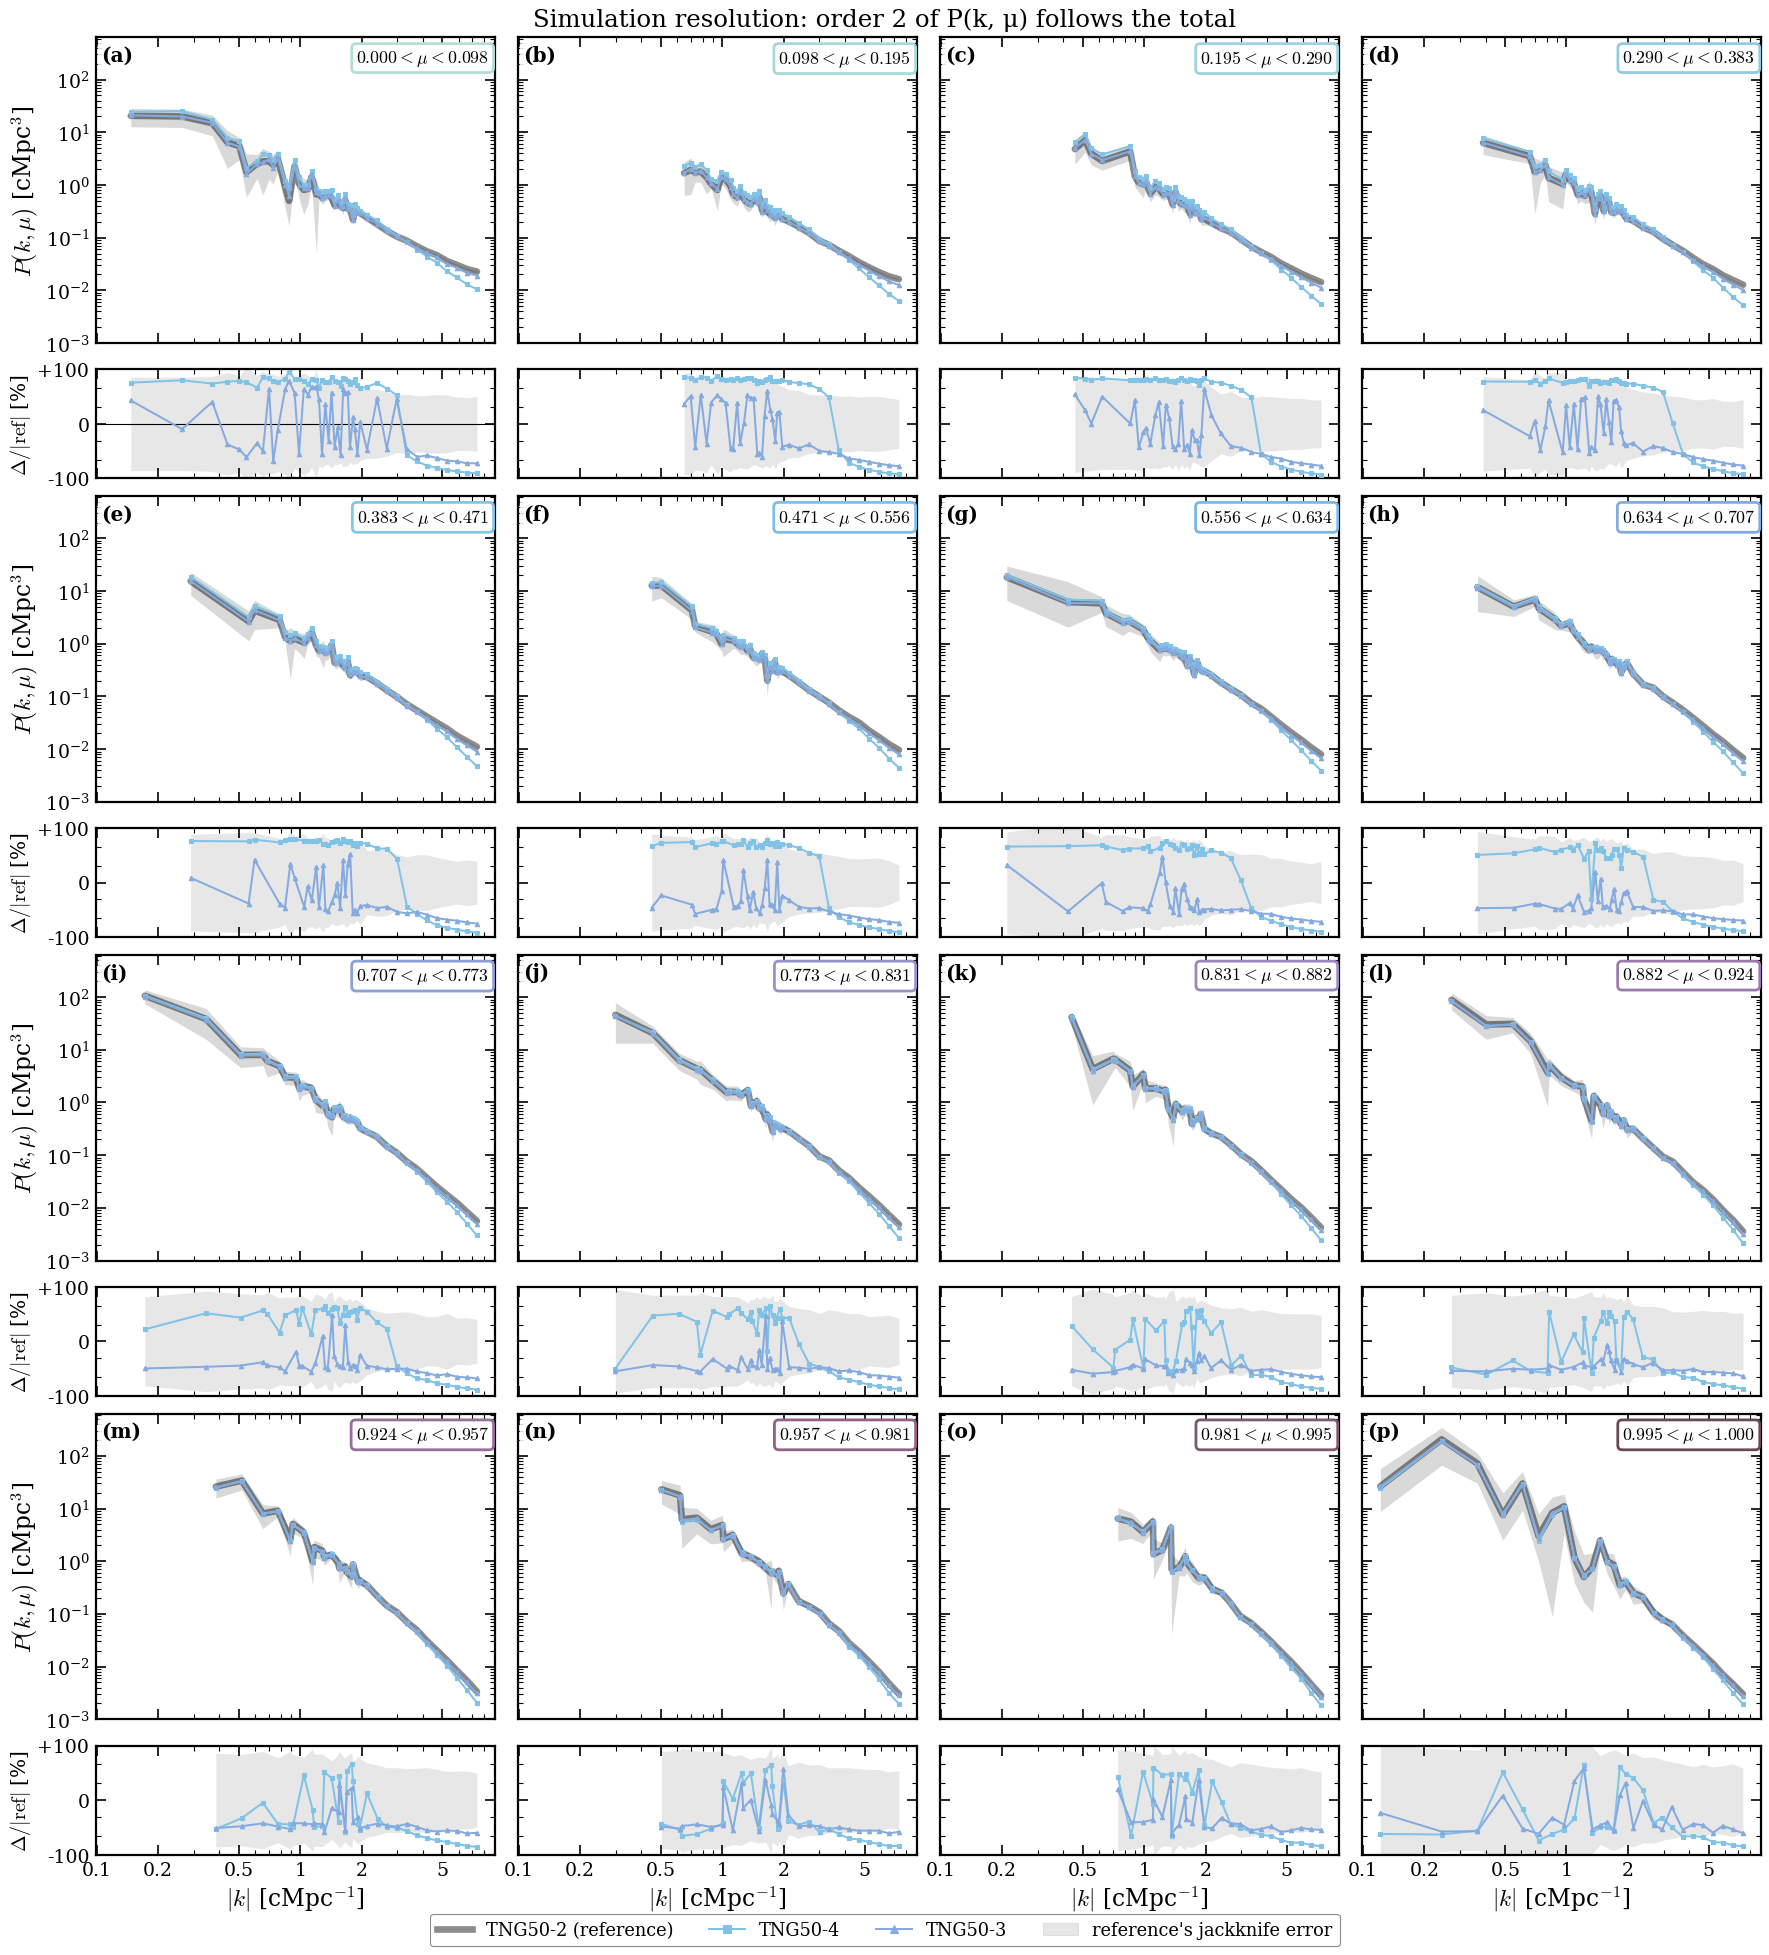

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        order 2                                10.7         75.3          22      34%
TNG50-3        order 2                                2.92         24.5          22      16%


In [9]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 2',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 2': "Simulation resolution: order 2 of P(k, μ) follows the total"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 2',), "P_mu"))

*Reading (order 2).* Order 2 carries the total: medians 10.7% (TNG50-4) and 2.9% (TNG50-3).

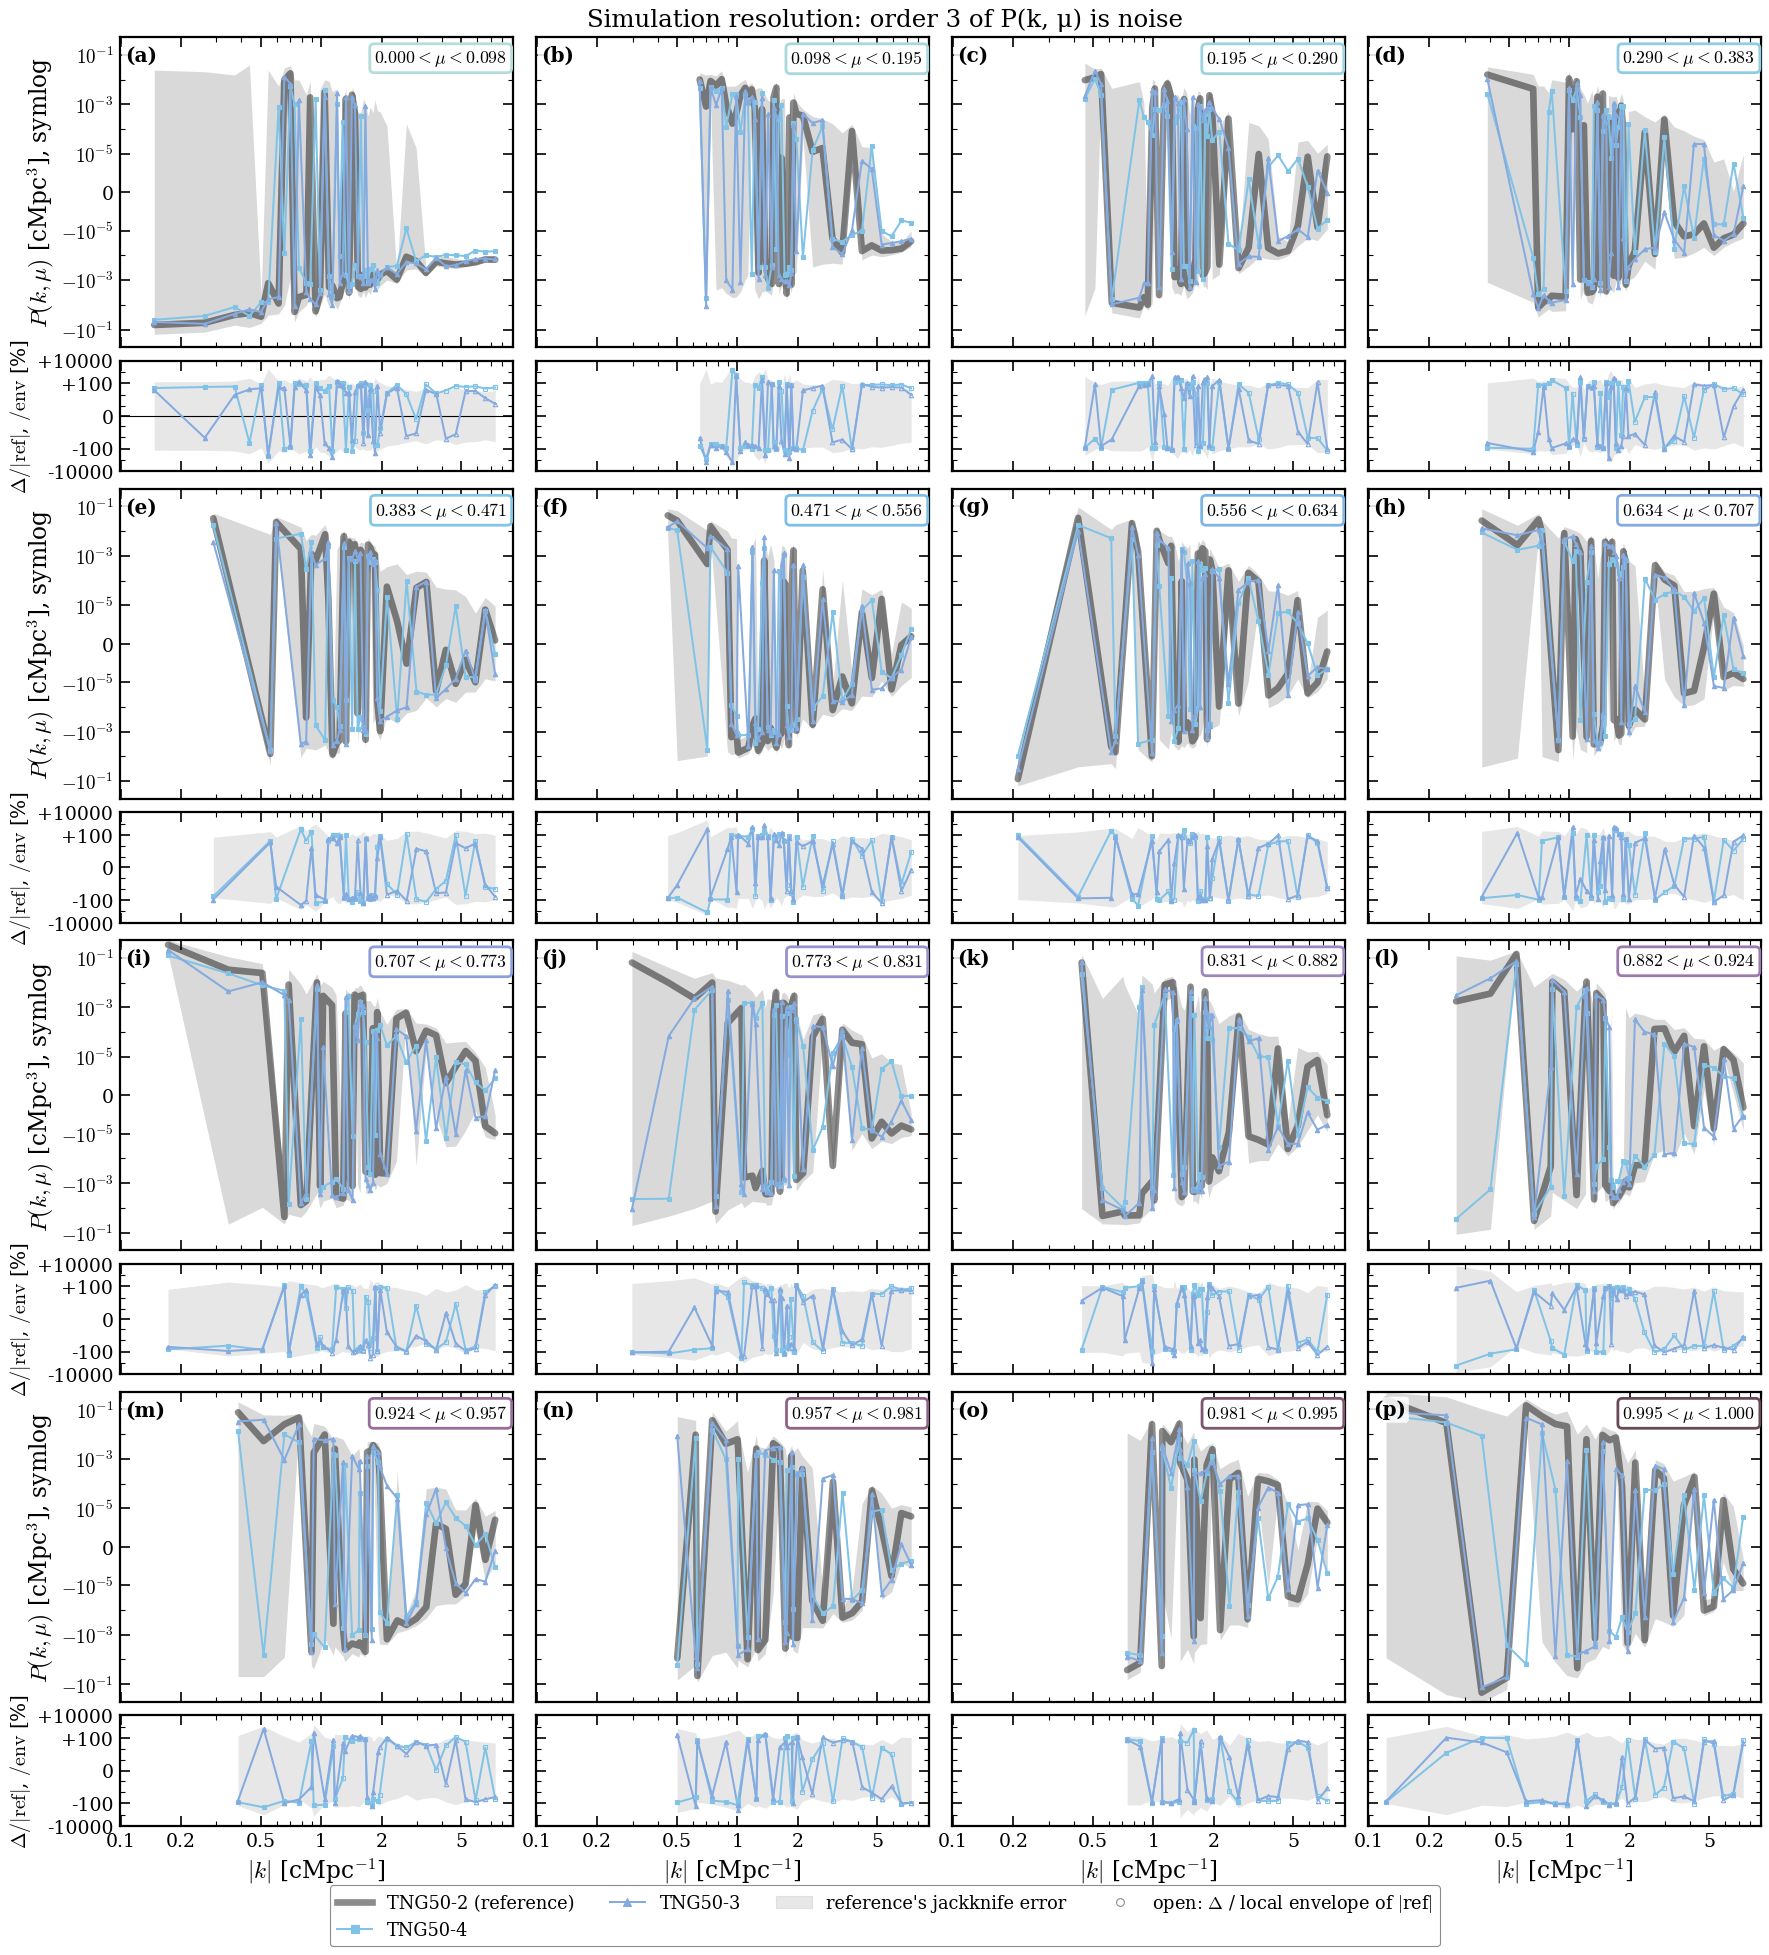

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        order 3                                66.2     1.68e+03         110      20%
TNG50-3        order 3                                45.7     1.57e+03         110      11%


In [10]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 3',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 3': "Simulation resolution: order 3 of P(k, μ) is noise"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 3',), "P_mu"))

*Reading (order 3).* Noise-dominated (error above 100% of its envelope); the departures (median 66%, 46%) are
mostly inside it.

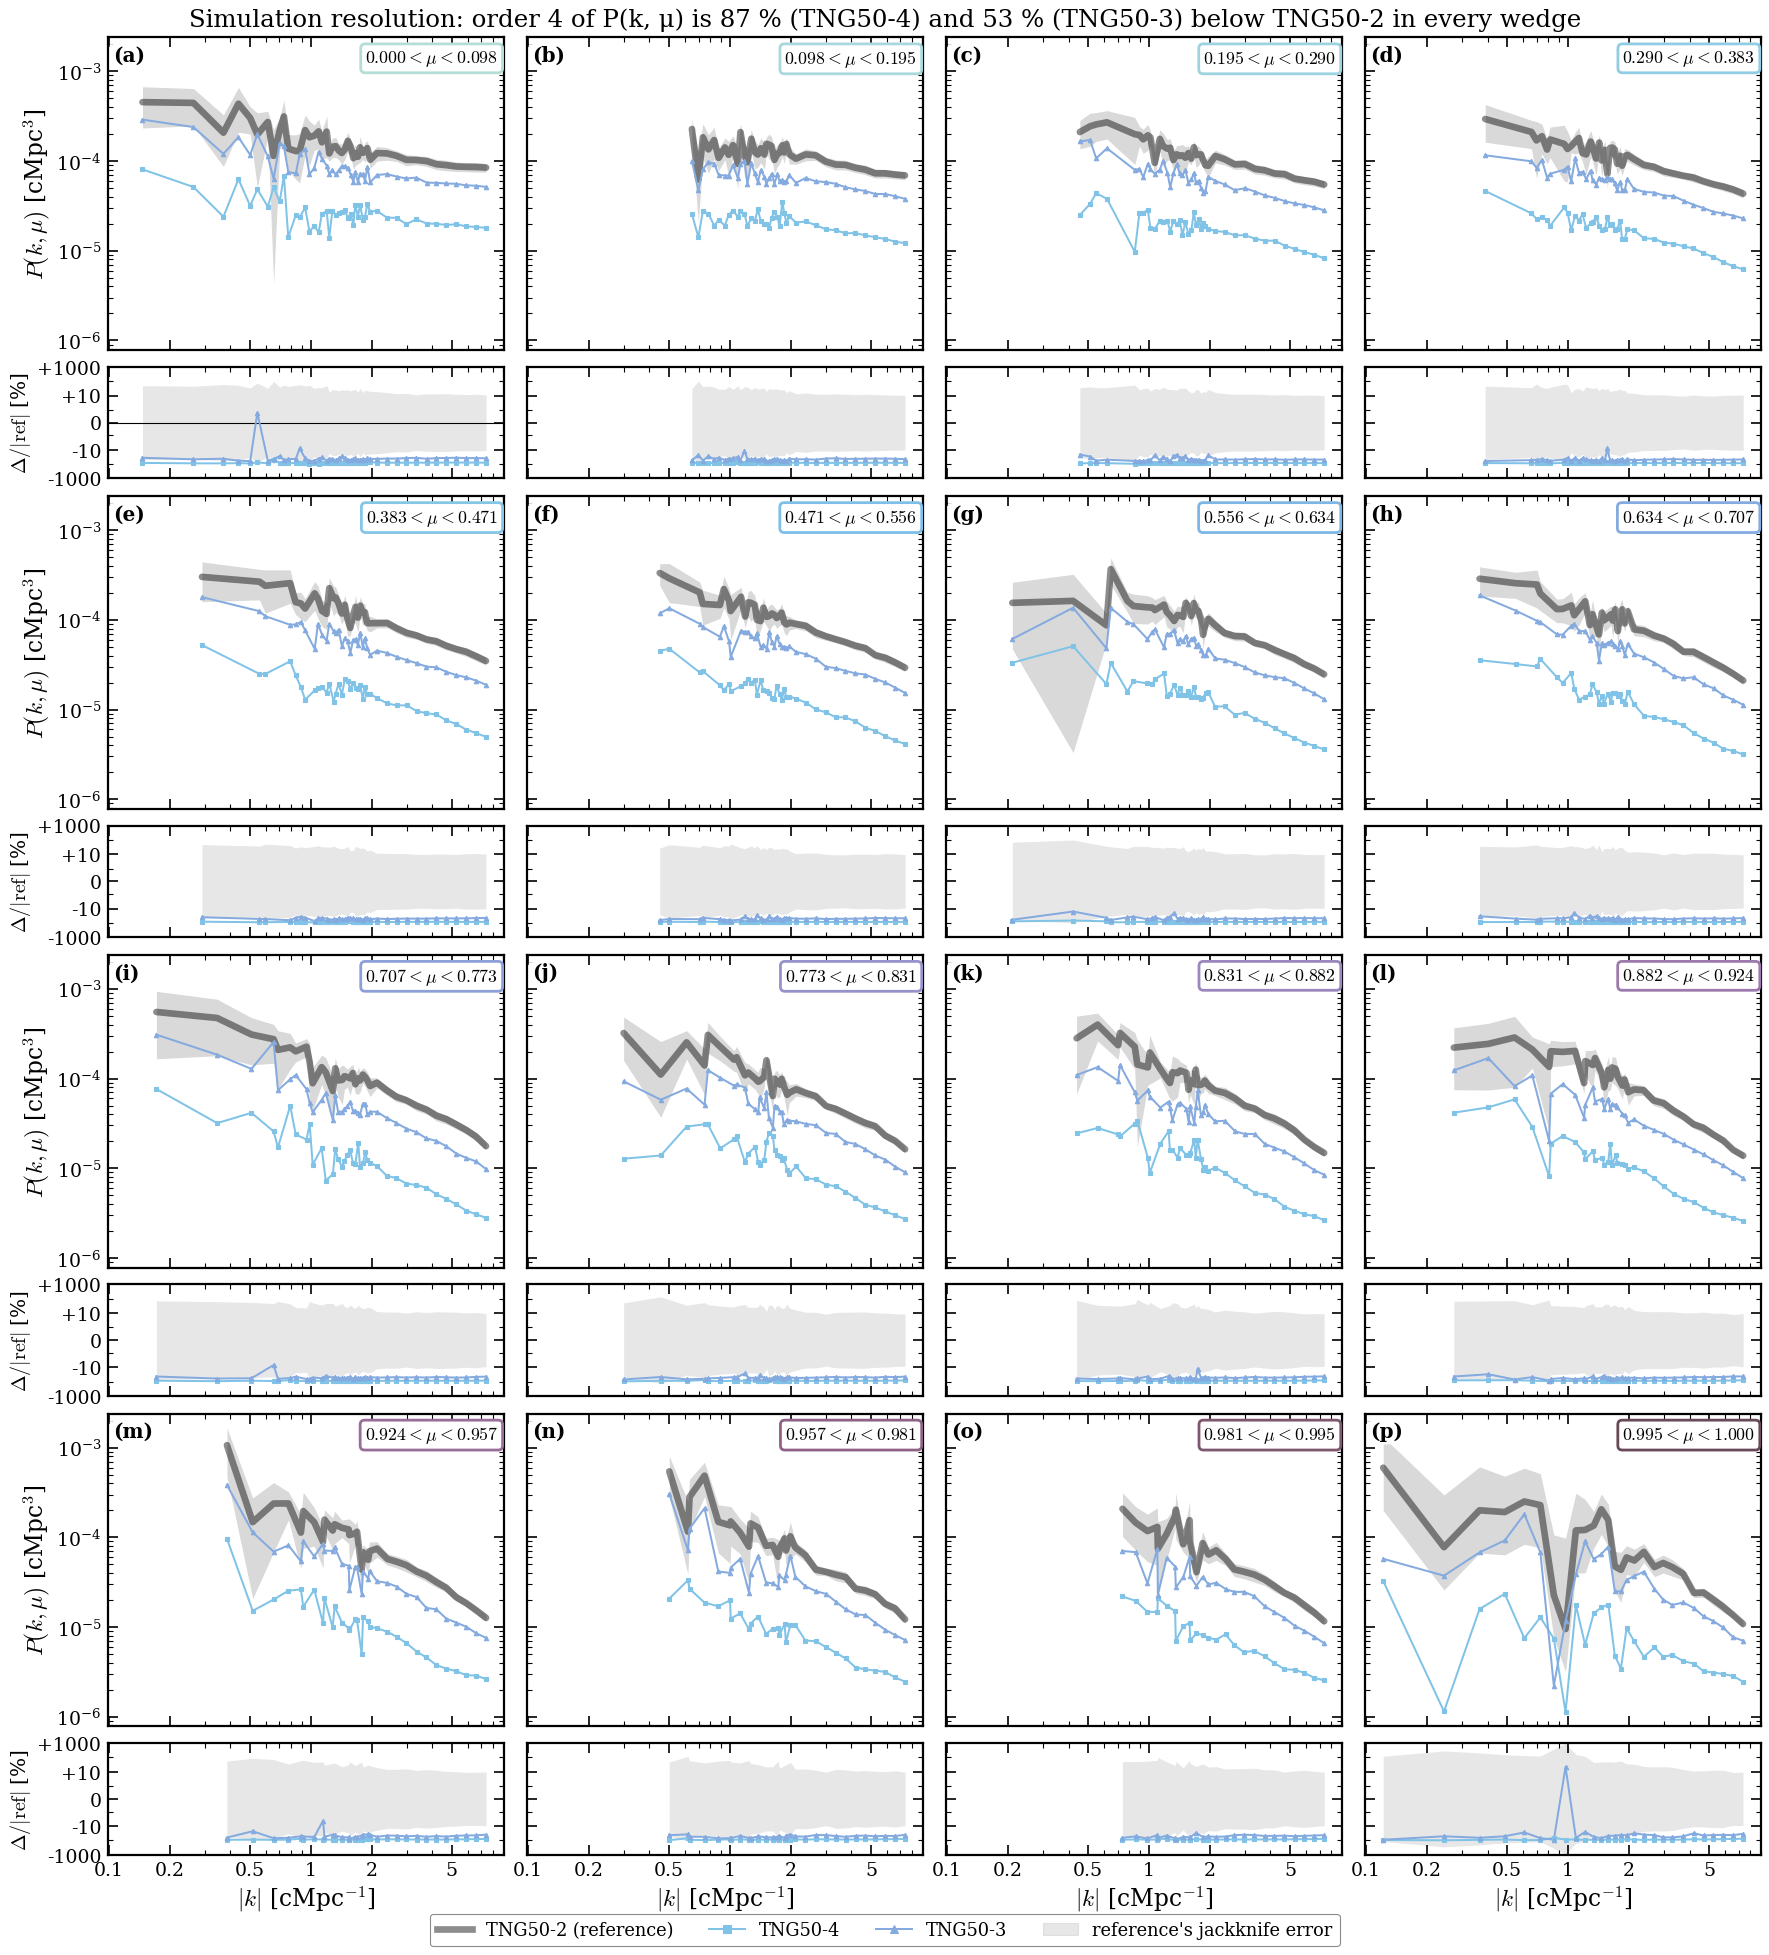

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        order 4                                86.3         98.5          25      97%
TNG50-3        order 4                                49.9         90.4          25      87%


In [11]:
fig, main, res = plot_runs_pk_mu_orders(CMP_T, STYLES, TERMS_REF, quantities=('order 4',), line_ids=LINE_IDS, labels=RUN_LABELS,
                                        linthresh=RES_LINTHRESH,
                                        titles={'order 4': "Simulation resolution: order 4 of P(k, μ) is 87 % (TNG50-4) and 53 % (TNG50-3) below TNG50-2 in every wedge"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, ('order 4',), "P_mu"))

*Reading (order 4).* Order 4 is far below TNG50-2 at every $|k|$ and in every wedge: $-87$% and $-53$% at
$|k| < 1$ cMpc$^{-1}$, $-85$% and $-47$% above 4 cMpc$^{-1}$; 97% and 87% of the bins outside the 25% error. It follows
the Si III absorption (E2).

### E2 · The wedges term by term (order 2)

One figure each for the $\mathrm{Ly}\alpha$ auto, the Si III auto and the cross term.

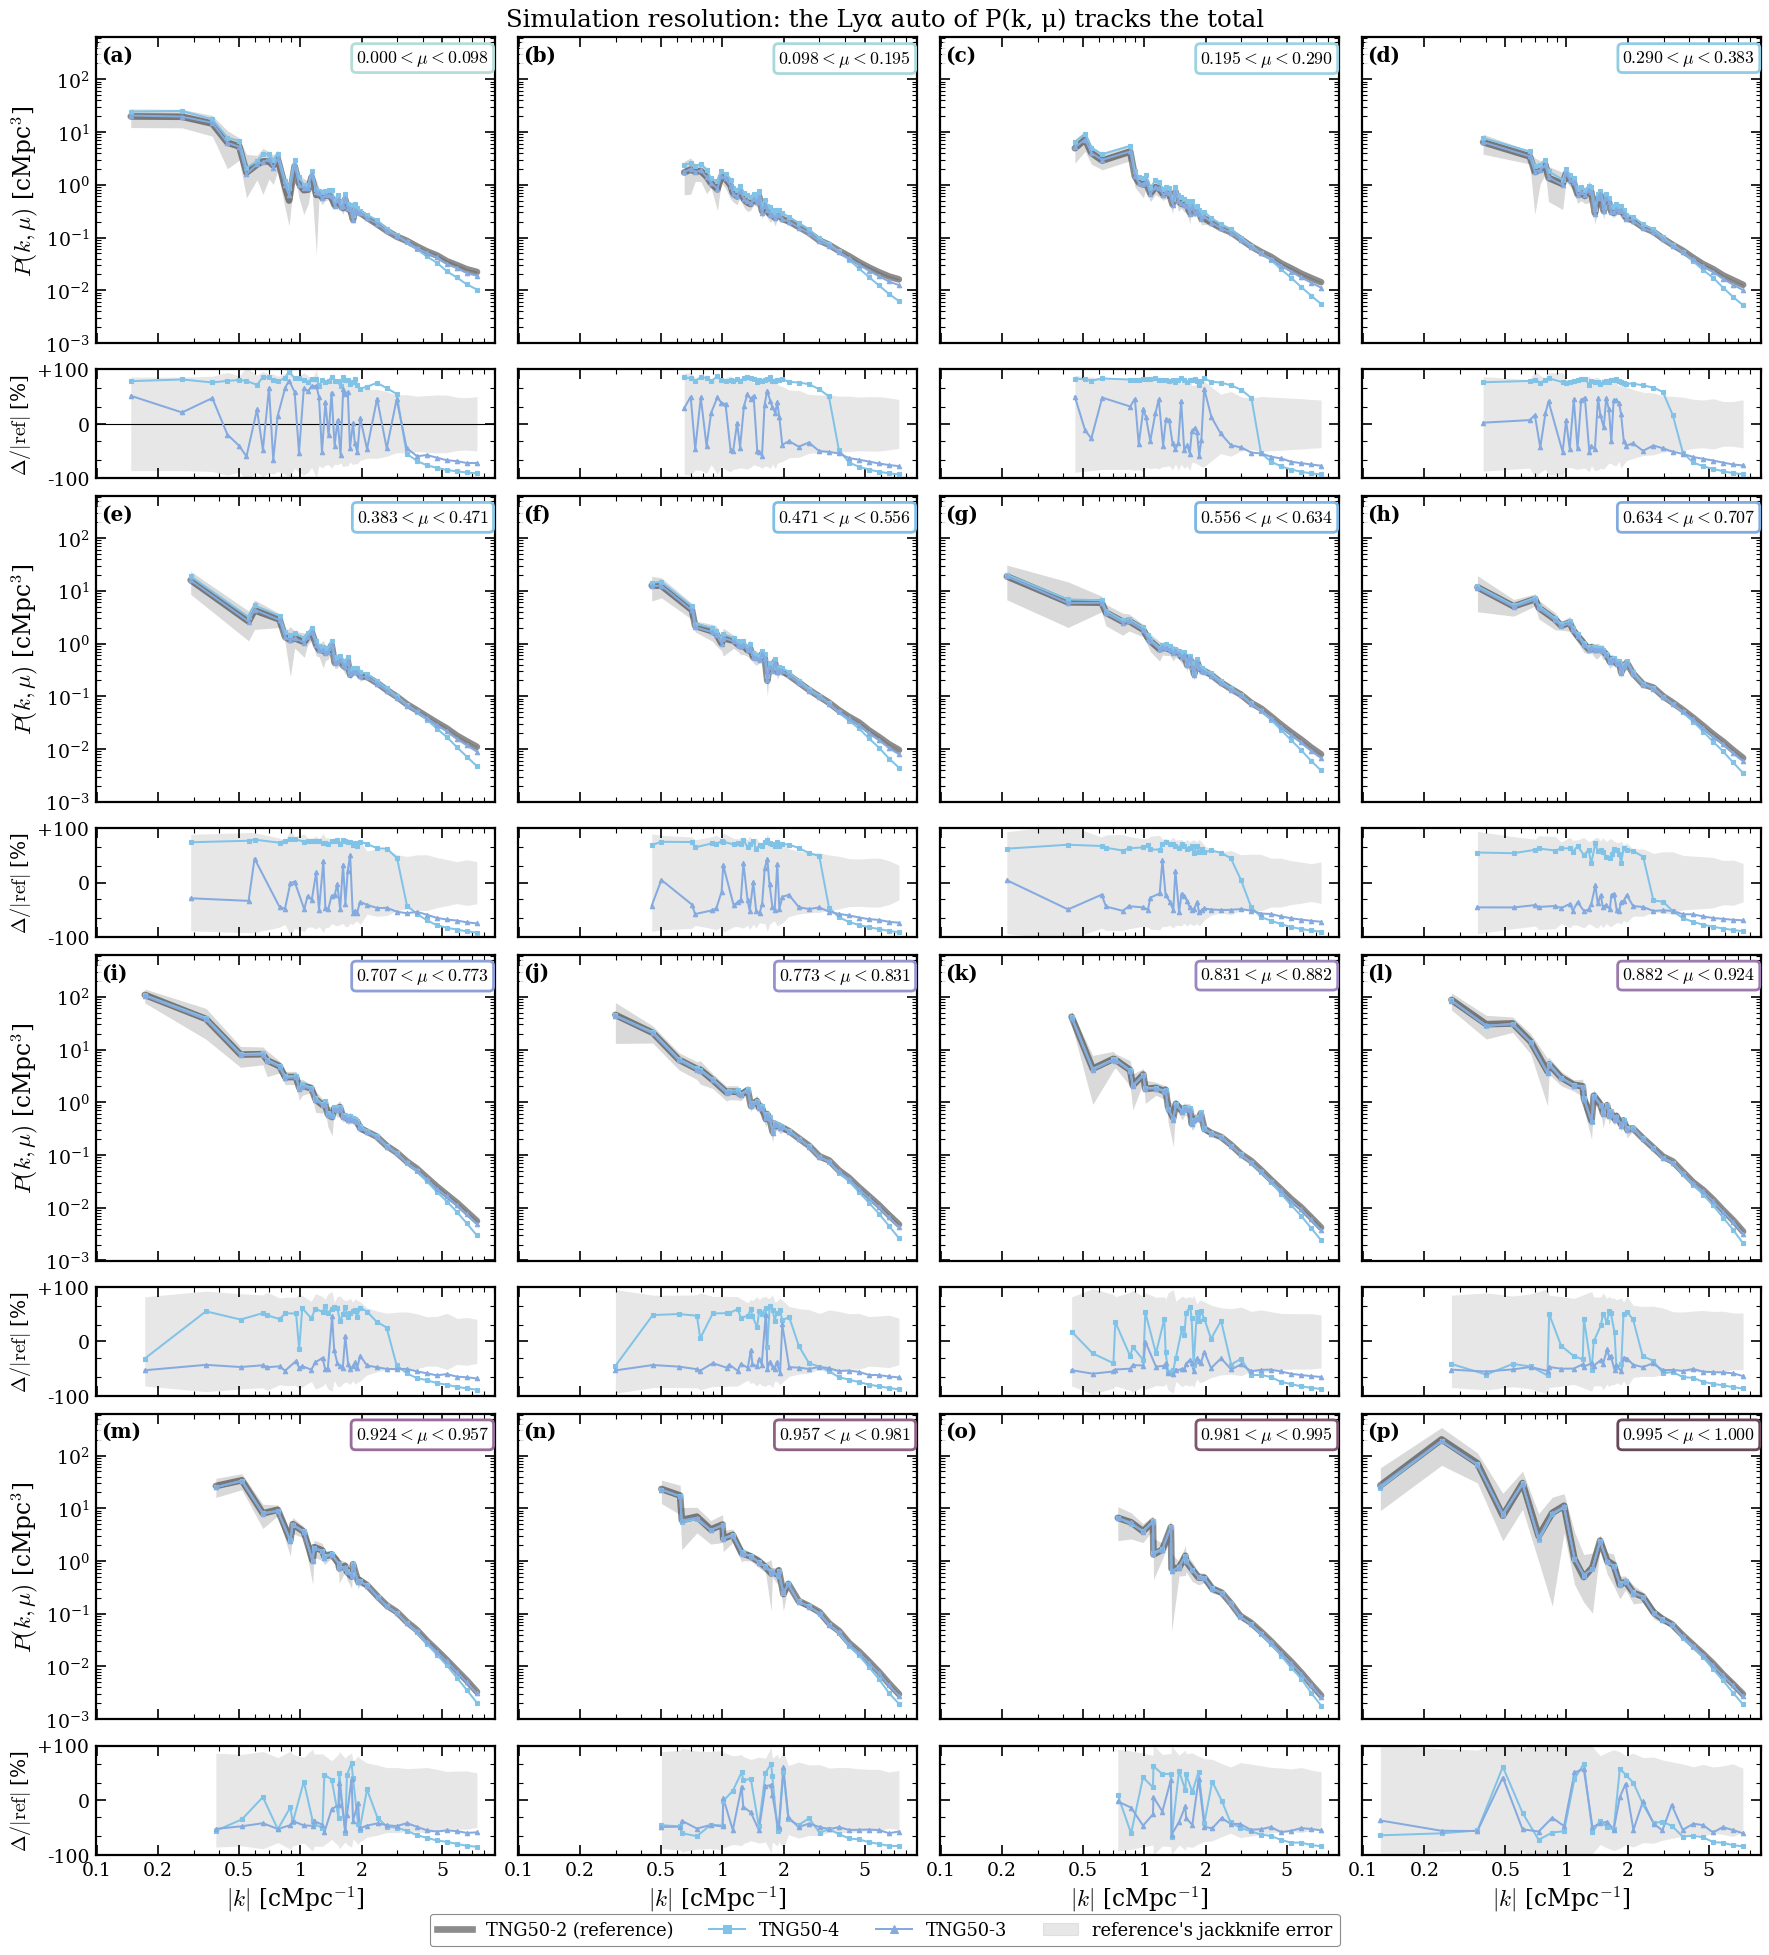

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        HI-LyA|HI-LyA                            11         75.6          22      34%
TNG50-3        HI-LyA|HI-LyA                          2.97         25.4          22      16%


In [12]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[0],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[0]: "Simulation resolution: the Lyα auto of P(k, μ) tracks the total"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[0],), "P_mu"))

*Reading (term 1).* $+8$% (TNG50-4) and $-2.3$% (TNG50-3) at $|k| < 1$ cMpc$^{-1}$, $-30$% and $-8$% above 4
cMpc$^{-1}$: the total's behaviour, which it sets.

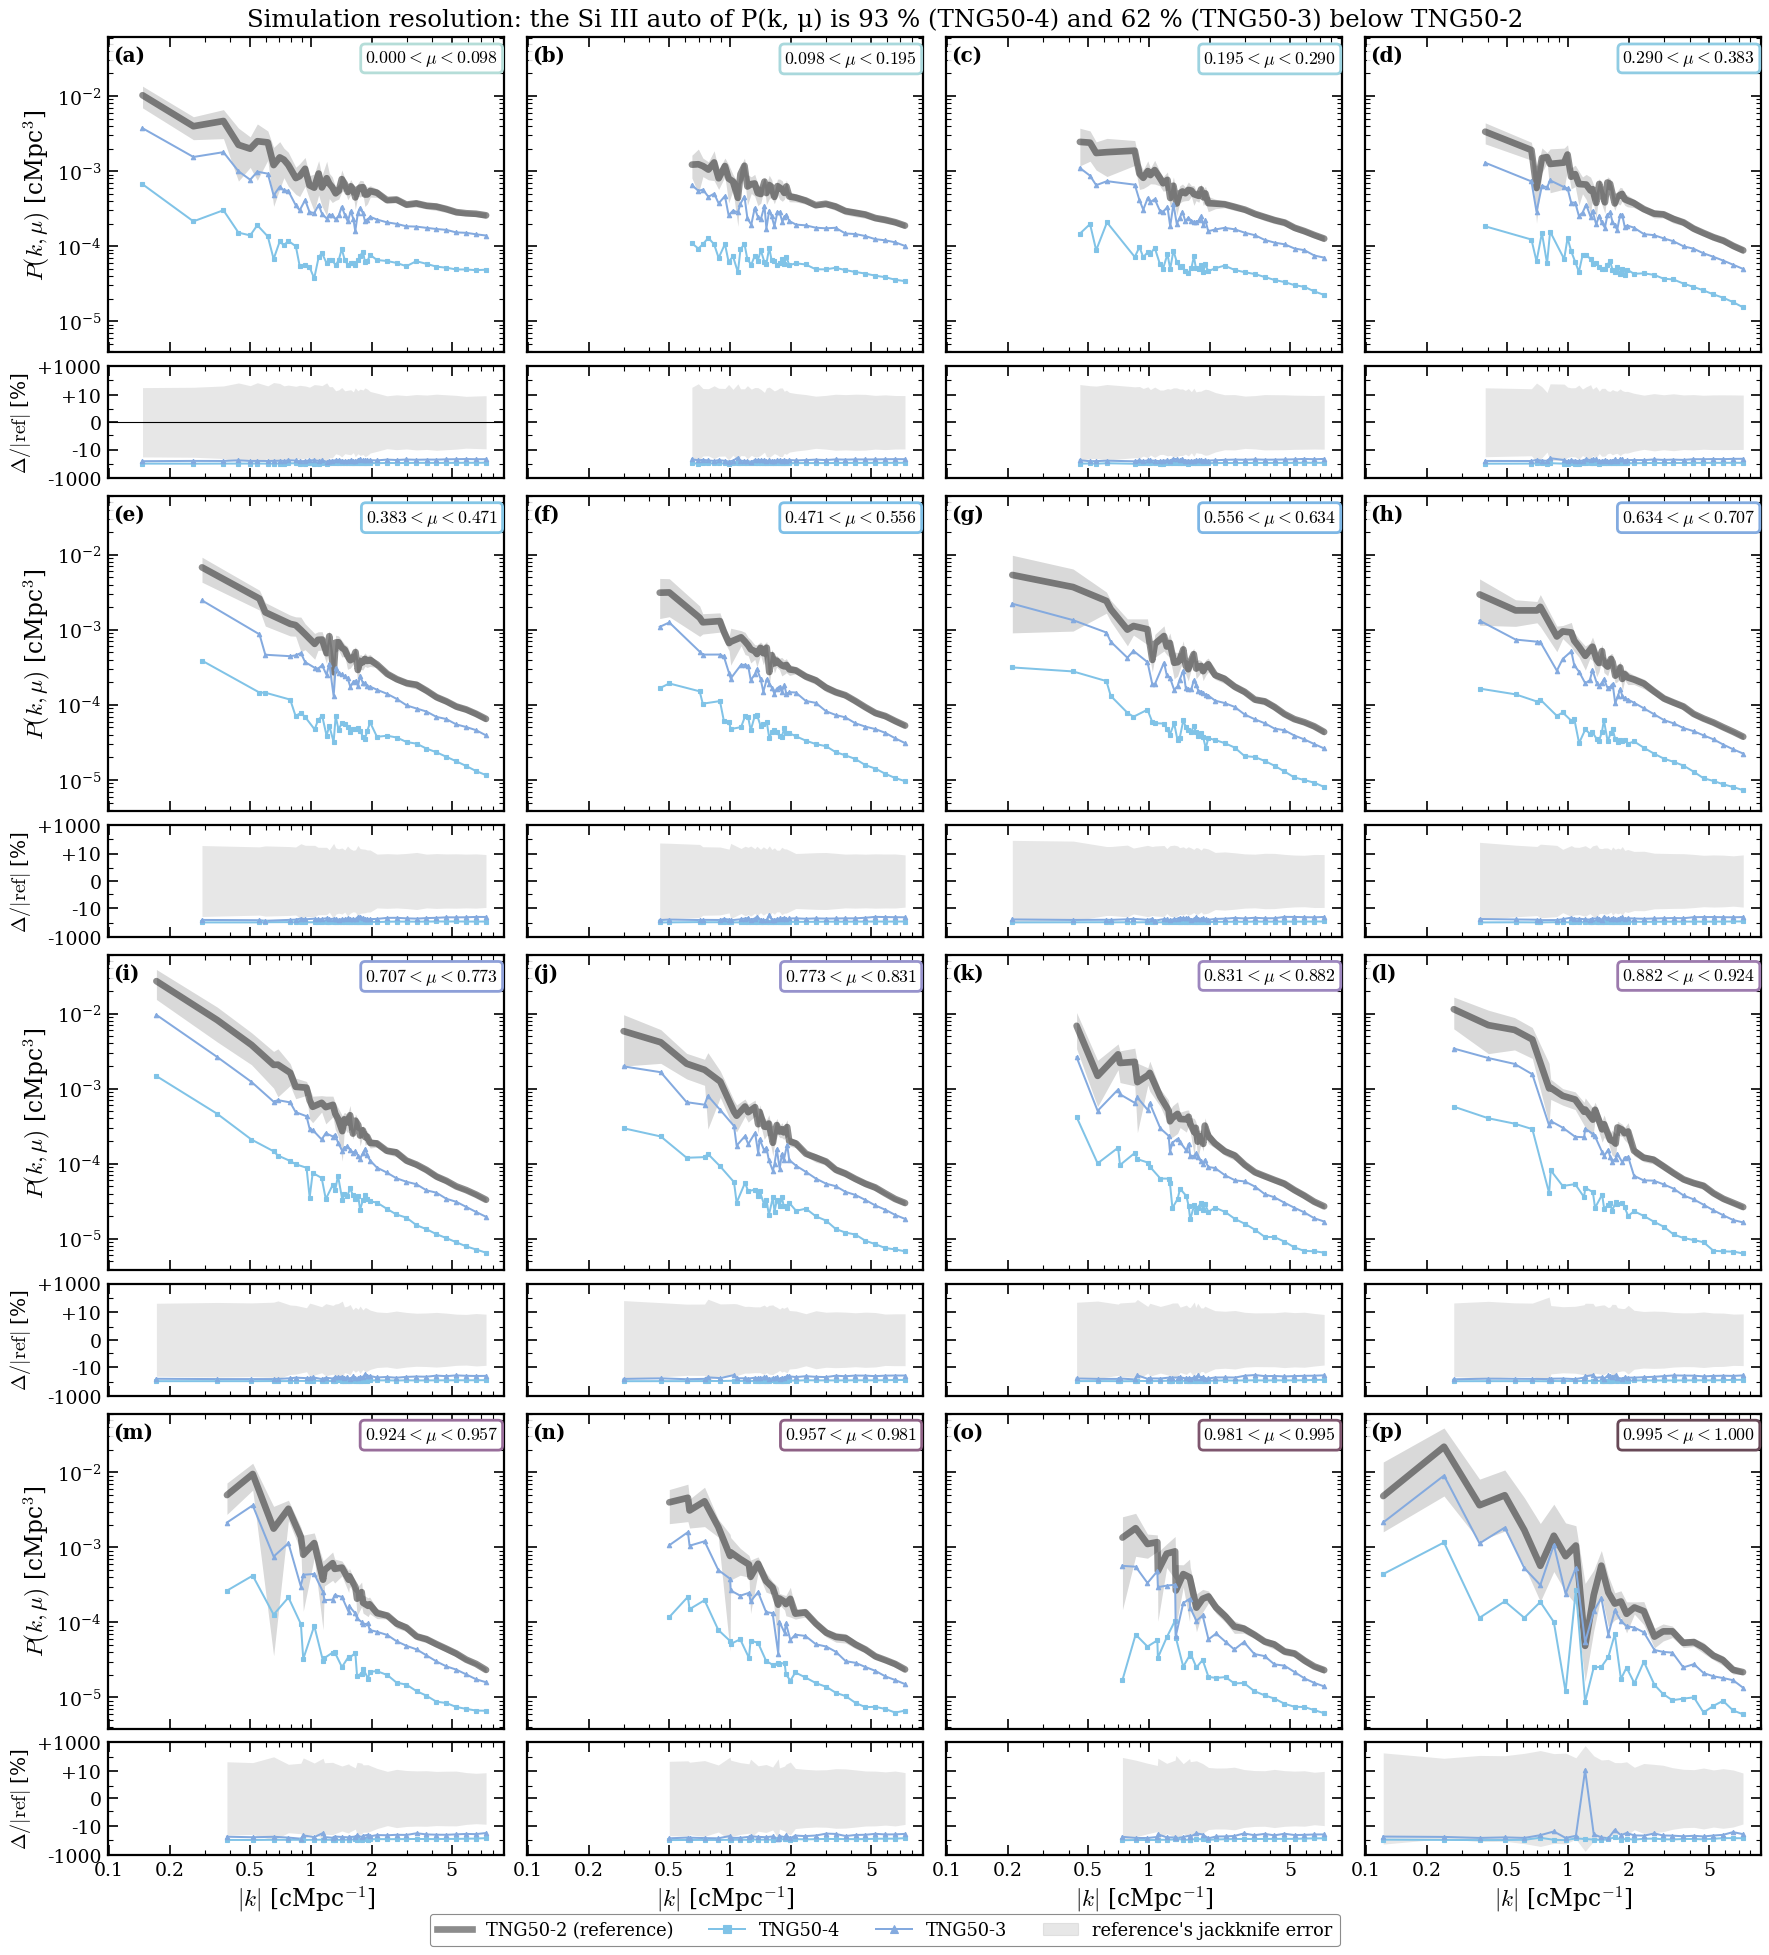

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        SiIII-1206|SiIII-1206                  88.6         98.7        23.5      98%
TNG50-3        SiIII-1206|SiIII-1206                    53         78.1        23.5      92%


In [13]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[1],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[1]: "Simulation resolution: the Si III auto of P(k, μ) is 93 % (TNG50-4) and 62 % (TNG50-3) below TNG50-2"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[1],), "P_mu"))

*Reading (term 2).* At $|k| < 1$ cMpc$^{-1}$ the Si III auto is $-93$% (TNG50-4) and $-62$% (TNG50-3), above 4
cMpc$^{-1}$ $-82$% and $-42$%: a factor 14 and 2.6, in every wedge, almost every bin outside the error. Si III is the
least converged quantity of the campaign.

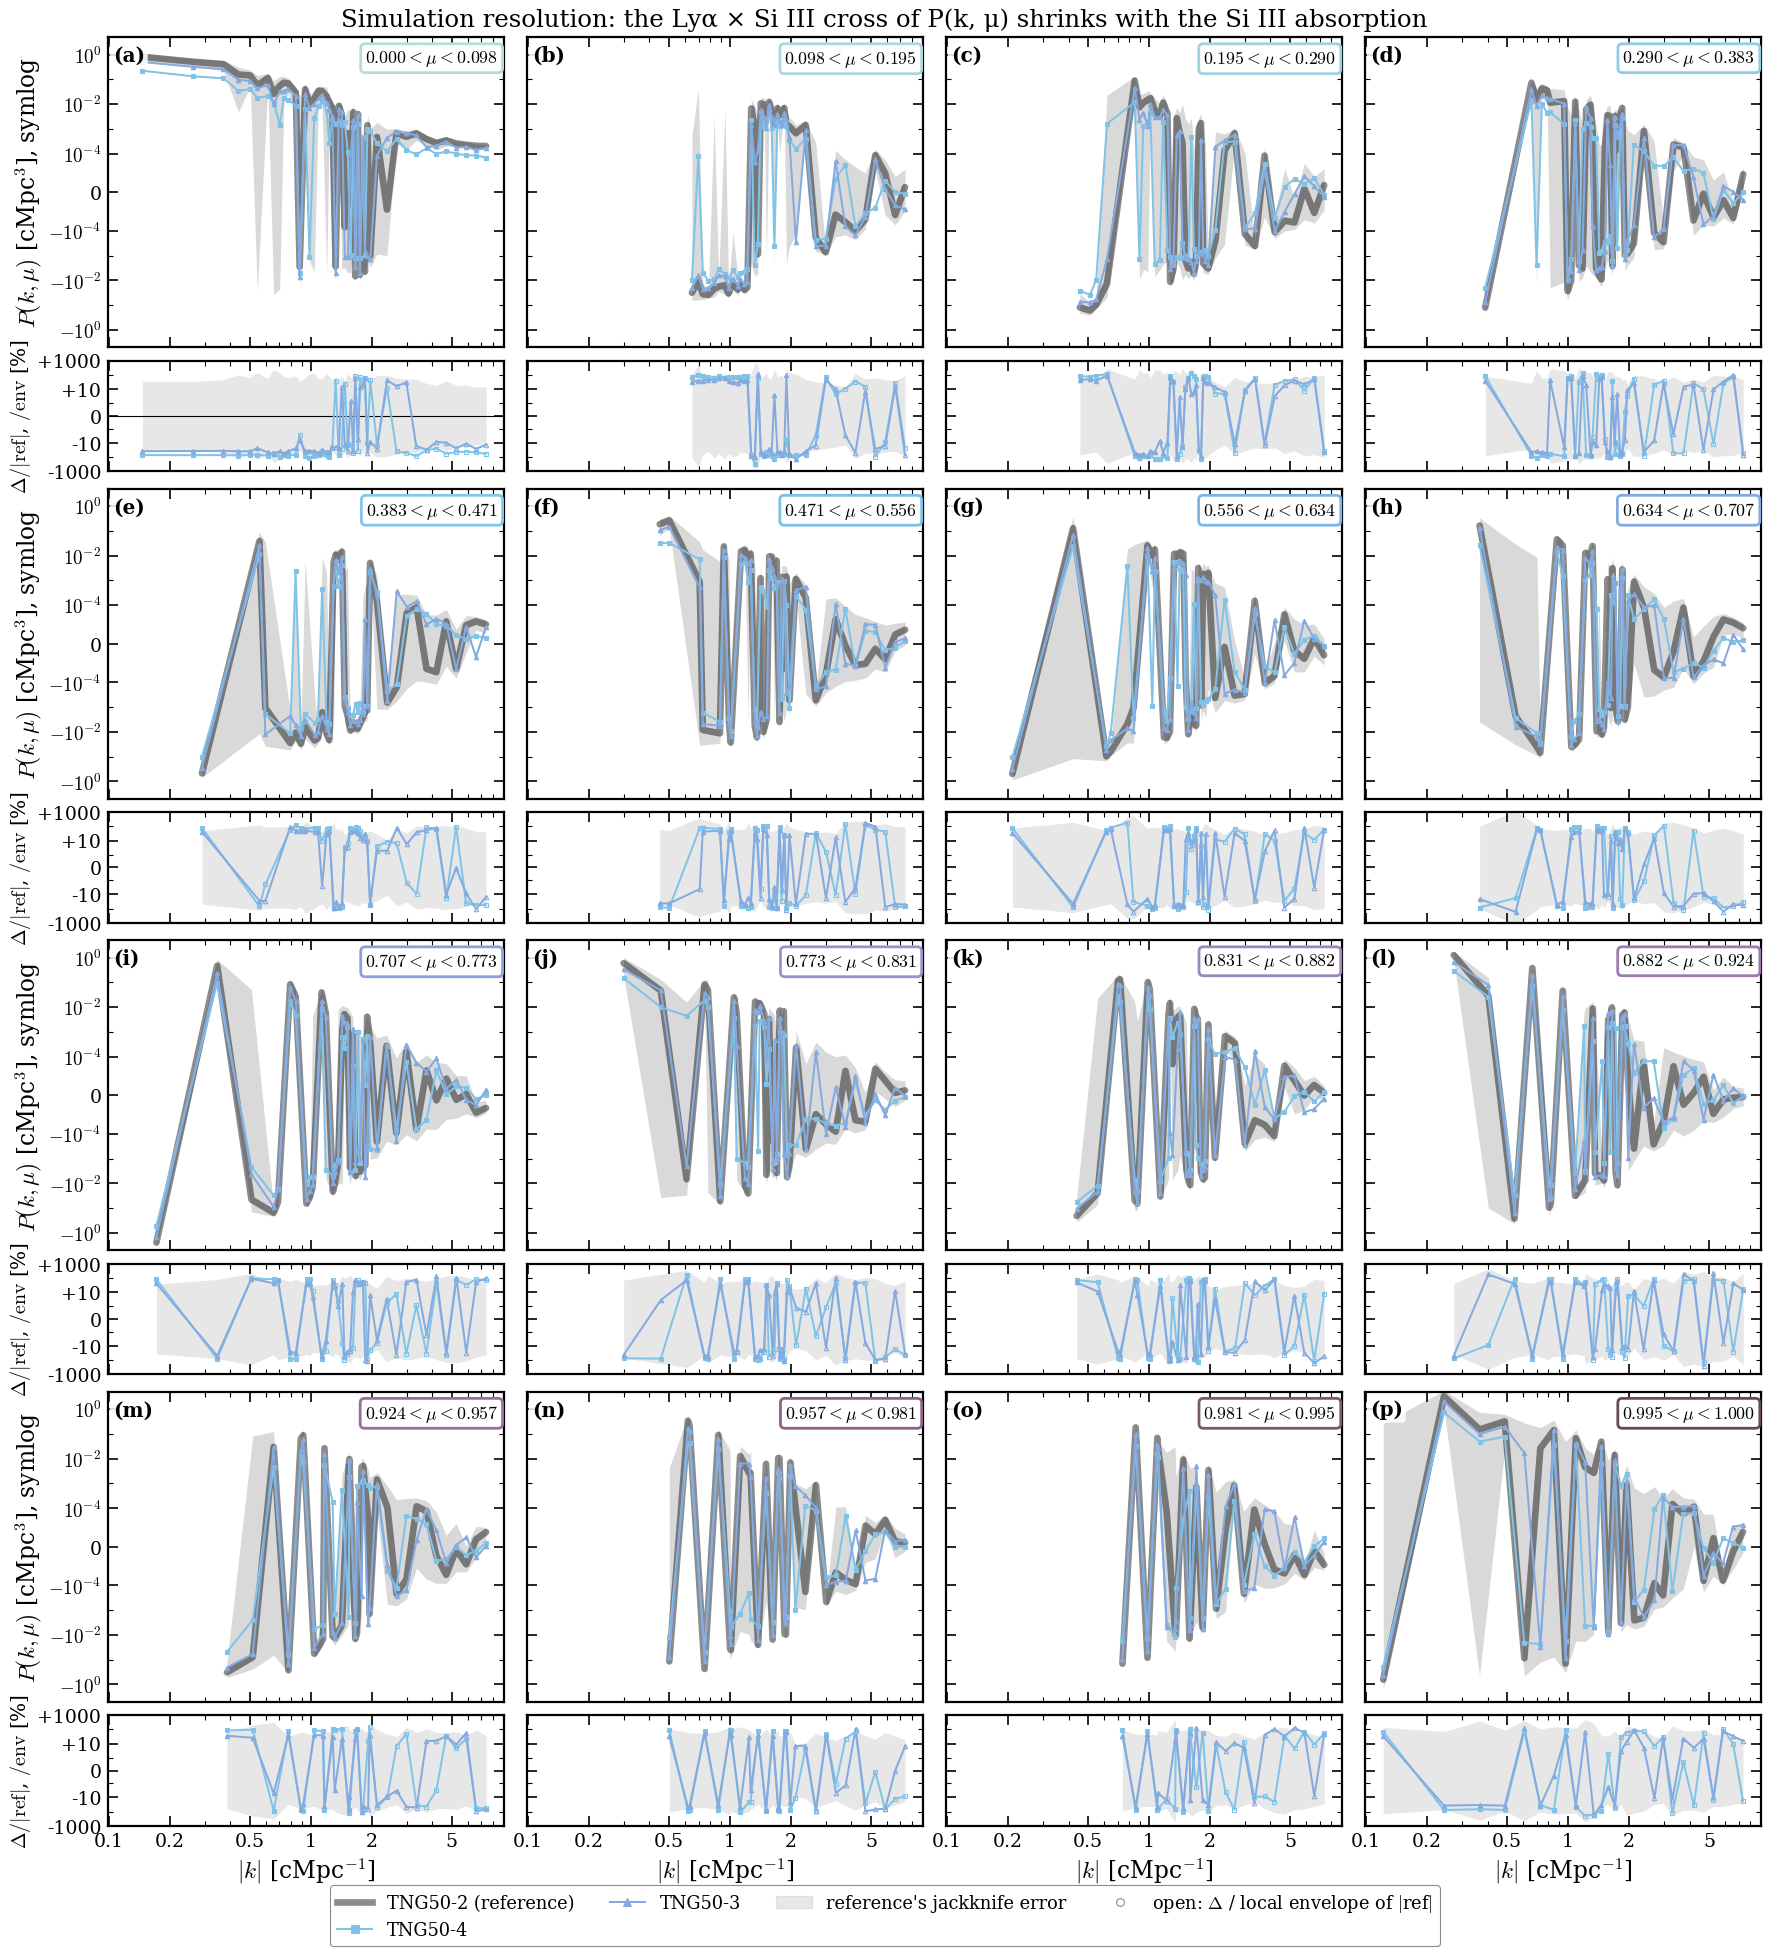

run            quantity                     median |d| [%]  max |d| [%] ref err [%]  outside
TNG50-4        HI-LyA|SiIII-1206                      65.9          316        67.3      35%
TNG50-3        HI-LyA|SiIII-1206                      38.3          270        67.3      16%


In [14]:
fig, main, res = plot_runs_pk_mu_terms(CMP_T, STYLES, TERMS_REF, terms=(TERMS[2],), line_ids=LINE_IDS, labels=RUN_LABELS,
                                       linthresh=RES_LINTHRESH, titles={TERMS[2]: "Simulation resolution: the Lyα × Si III cross of P(k, μ) shrinks with the Si III absorption"})[0]
add_panel_letters(main)
plt.show()
print(format_terms_table(CMP_T, (TERMS[2],), "P_mu"))

*Reading (term 3).* The cross departs by a median 66% (TNG50-4) and 38% (TNG50-3) of its envelope, inside its 67%
error in most bins: noisier than the autos, it follows the drop of Si III.

## Part F — The converged range

For every run and statistic, the largest $k$ up to which **every** bin differs from the reference by less than 0.1%,
0.5% and 1% (`k_max_table`: P1D on its native modes, $P(k, \mu)$ on its $|k|$ bins; "$\geq k$" when every bin passes up to
the run's last one; 0 when the first bin already fails). The last columns give the run's last bin and the median
jackknife error of the relative difference: a $k_{\max}$ set by bins whose difference is within that error is limited
by noise, not by the parameter. The figure draws $k_{\max}(0.5\%)$ against the number of gas cells of the simulation.

against TNG50-2; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes up to the run's last one; the DESI DR1 P1D reaches k = 0.032 s/km at z = 3.0
run            statistic                         k_max(0.1%)    k_max(0.5%)      k_max(1%)  last bin jk err [%]  unit
TNG50-4        P1D HI-LyA                                  0              0              0      3.14         55  s/km
TNG50-4        P1D SiIII-1206                              0              0              0      3.14        3.8  s/km
TNG50-4        P1D total                                   0              0              0      3.14        3.9  s/km
TNG50-4        P(k, mu) total mu 0.00-0.50                 0              0              0      7.38          3  1/cMpc
TNG50-4        P(k, mu) total mu 0.50-0.80                 0              0          0.172      7.38        2.2  1/cMpc
TNG50-4        P(k, mu) total mu 0.80-0.95                 0              0              0      7.38  

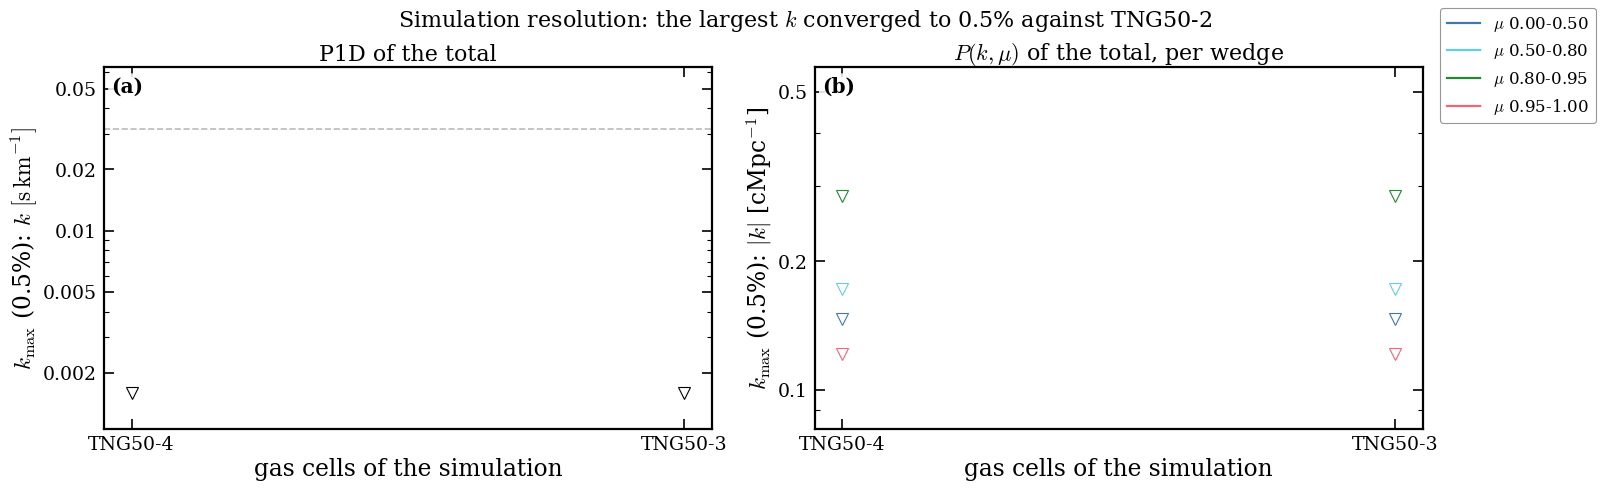

In [15]:
ROWS = k_max_table(CMP_ALL, TOLS)
print(f"against {REFERENCE}; P1D on its native modes [s/km], P(k, mu) on its |k| bins [1/cMpc]; '>= k': every bin passes "
      f"up to the run's last one; the DESI DR1 P1D reaches k = {K_DESI:.3f} s/km at z = {P1D_REF['z']}")
print(format_k_max_table(ROWS, TOLS))
fig, axs = plot_k_max_summary(ROWS, X_OF_RUN, xlabel=X_LABEL, xscale=X_SCALE, xticks=X_TICKS, tol=0.005, p1d_k_ref=K_DESI,
                              title=f"{TITLE_STEM}: the largest $k$ converged to 0.5% against {RUN_LABELS[REFERENCE]}")
add_panel_letters(axs)
plt.show()

**Reading.** Stated with caution: three resolutions a factor 8 apart in mass, and no rescaling of the mean flux.

* **Mean transmission:** TNG50-4 $-1.09 \pm 0.16$% and TNG50-3 $+1.45 \pm 0.07$% relative to TNG50-2, so it is not
  monotonic with resolution.
* **$\mathrm{Ly}\alpha$ $P_\mathrm{1D}$ within the DESI range:** steps of 7.4% ($-4 \to -3$) and 7.5% ($-3 \to -2$). The steps do
  not shrink ($q \approx 1.2$), so TNG50-2 is not converged at the per-cent level. With $q$ this close to 1 the
  geometric extrapolation printed above ($\sim$40%) is not meaningful.
* **Si III $P_\mathrm{1D}$:** changes by a factor 2–3 per step. It traces dense, enriched gas, which these resolutions
  resolve poorly.
* **$P(k, \mu)$:**
  * TNG50-3 is a few per cent below TNG50-2 up to $\sim$3 cMpc$^{-1}$, and 10–20% below at 7 cMpc$^{-1}$;
  * TNG50-4 is 10–20% above at low $|k|$ in the transverse wedges and up to 50% below at 7 cMpc$^{-1}$;
  * no bin is within 0.5%.
* **Per skewer:** the flux correlates with TNG50-2 at a median 0.985 (TNG50-3) and 0.939 (TNG50-4).

The resolution of the simulation is the largest effect of the four sweeps by orders of magnitude. A comparison of shapes
should first match the mean flux (rescale $\tau$), which this notebook does not do.